# CS3807 – Deep Learning Lab · Experiments 8 & 9
## Effect of Attention Type and Attention Position in a Pretrained ResNet50 (tf_flowers)

**What this notebook does (everything in the lab sheet, in one run)**

| Lab section | What is executed |
|---|---|
| §14 Exp-1 | Attention type ablation A0–A5 at P3 |
| §15 Exp-2 | Attention position ablation B1–B4 (Channel→Spatial at P1, P2, P3, P4) |
| §16 Exp-3 | Multiple positions: P3, P4, P3+P4, P2+P3+P4 |
| §17 Exp-4 | Attention order: Channel→Spatial vs Spatial→Channel |
| §18 Exp-5 | Spatial kernel size k ∈ {3, 5, 7} |
| §19, 36 | Additional mechanisms: ECA, CBAM, Coordinate Attention (SE ≡ the lab's channel attention) |
| §22–23, 38 | **All tables** (CSV + LaTeX), incl. params, trainable params, inference time |
| §24–32 | **All figures** (curves, bars, scatter, confusion matrices, feature maps, channel/spatial/self-attention maps, Grad-CAM, position maps) |

**Outputs** (inside `lab8_outputs/`): `figures/*.eps` (saved at **600 dpi**), `tables/*.csv` + `tables/*.tex`, `results/*.json` (raw per-model results), `checkpoints/`.

**Run time:** the notebook benchmarks your hardware first and picks the *smallest sensible number of epochs* so that all 17 trainings + all figures fit in `TARGET_HOURS` (default 2.0 h). **A CUDA GPU is strongly recommended.** The notebook is resumable: if it stops, just re-run all cells and finished models are skipped.

**Tip:** set `QUICK_TEST = True` in the config cell first for a ~10-minute smoke test, then set it back to `False` for the real run.

In [2]:
# If a package is missing, uncomment and run once:
# !pip install torch torchvision numpy pandas matplotlib scikit-learn pillow

import os, sys, json, time, math, random, gc, tarfile, urllib.request, shutil, warnings, contextlib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from IPython.display import display

%matplotlib inline
print('torch', torch.__version__, '| torchvision', torchvision.__version__)

torch 2.14.1+cu126 | torchvision 0.29.1+cu126


In [6]:
%pip uninstall -y torch torchvision torchaudio

Found existing installation: torch 2.10.0
Uninstalling torch-2.10.0:
  Successfully uninstalled torch-2.10.0
Found existing installation: torchvision 0.25.0
Uninstalling torchvision-0.25.0:
  Successfully uninstalled torchvision-0.25.0
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.
You can safely remove it manually.


In [1]:
%pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126

Looking in indexes: https://download.pytorch.org/whl/cu126
  Using cached https://download-r2.pytorch.org/whl/cu126/torch-2.14.1%2Bcu126-cp312-cp312-win_amd64.whl.metadata (37 kB)
  Using cached https://download-r2.pytorch.org/whl/cu126/torchvision-0.29.1%2Bcu126-cp312-cp312-win_amd64.whl.metadata (5.8 kB)
  Using cached https://download-r2.pytorch.org/whl/cu126/torchaudio-2.11.0%2Bcu126-cp312-cp312-win_amd64.whl.metadata (7.0 kB)
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB 23.5 MB/s eta 0:01:51
   ---------------------------------------- 0.0/2.6 GB 31.6 MB/s eta 0:01:22
   ---------------------------------------- 0.0/2.6 GB 32.7 MB/s eta 0:01:20
   ---------------------------------------- 0.0/2.6 GB 32.2 MB/s eta 0:01:20
   ---------------------------------------- 0.0/2.6 GB 31.5 MB/s eta 0:01:22
    --------------------------------------- 0.0/2.6 GB 32.9 MB/s eta 0:01:18
    ------------------------------

In [3]:
# ============================== CONFIGURATION ==============================
QUICK_TEST    = False   # True -> tiny smoke test (~10 min) to check that everything runs
PRETRAINED    = True    # ImageNet weights (internet needed the first time)
SEED          = 42
IMG_SIZE      = 224
BATCH_SIZE    = 32
DROPOUT       = 0.3
LR_HEAD       = 1e-3    # phase 1: new layers (attention + classifier); backbone frozen
LR_FT         = 1e-4    # phase 2: fine-tune conv5_x (layer4) + attention + classifier
GAMMA_LR_MULT = 10      # only the self-attention scalar gamma (init 0) gets x10 LR
GATE_BIAS     = 2.0     # attention gates start near identity (sigmoid(2)=0.88) so the pretrained
                        # features are not destroyed at step 0 (same for every attention type)
REDUCTION     = 16      # channel-attention reduction ratio r
USE_AMP       = True    # mixed precision on CUDA

# ---- epoch control: None -> picked automatically from a speed benchmark ----
TARGET_HOURS     = 2.0                       # total wall-clock budget for the whole notebook
EPOCHS_HEAD      = None                      # set both to integers to force your own values
EPOCHS_FT        = None
EPOCH_CANDIDATES = [(4, 6), (3, 5), (3, 4), (2, 4), (2, 3), (2, 2), (1, 2), (1, 1)]  # (head, finetune)
VIZ_RESERVE_MIN  = 12                        # minutes reserved for Grad-CAM / attention figures
ATTN_OVERHEAD    = 1.25                      # safety factor for attention modules in the estimate

EPS_DPI          = 600
TIMING_RUNS      = 100                       # runs for the inference-time measurement
CAM_EVAL_N       = 200                       # test images used for the Grad-CAM coverage table
QUICK_PER_CLASS  = 24

if QUICK_TEST:
    EPOCHS_HEAD, EPOCHS_FT = 1, 1
    TIMING_RUNS, CAM_EVAL_N = 10, 20

OUT_DIR  = Path('lab8_outputs_quicktest' if QUICK_TEST else 'lab8_outputs')
DATA_DIR = Path('data')
FIG_DIR, TAB_DIR, RES_DIR, CKPT_DIR = (OUT_DIR / d for d in ('figures', 'tables', 'results', 'checkpoints'))
for d in (OUT_DIR, FIG_DIR, TAB_DIR, RES_DIR, CKPT_DIR, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ------------------------------- device --------------------------------
if torch.cuda.is_available():
    DEVICE = torch.device('cuda'); torch.backends.cudnn.benchmark = True
elif getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
AMP = bool(USE_AMP and DEVICE.type == 'cuda')
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '', '| AMP:', AMP)
if DEVICE.type == 'cpu':
    print('WARNING: no GPU found. Training 17 ResNet50 models on CPU will be far slower than 2.5 hours.')

# ------------------------------ matplotlib ------------------------------
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': EPS_DPI, 'font.size': 9, 'axes.titlesize': 10,
    'axes.labelsize': 9, 'legend.fontsize': 8, 'legend.framealpha': 1.0,   # EPS has no transparency
    'ps.fonttype': 42, 'pdf.fonttype': 42, 'axes.grid': False,
})

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def sync():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    elif DEVICE.type == 'mps': torch.mps.synchronize()

def save_fig(fig, name):
    """Save as EPS @ 600 dpi (vector + 600-dpi raster parts), then show inline."""
    path = FIG_DIR / f'{name}.eps'
    fig.savefig(path, format='eps', dpi=EPS_DPI, bbox_inches='tight')
    plt.show(); plt.close(fig)
    print(f'  saved -> {path}')

def _fmt(v):
    if isinstance(v, (float, np.floating)): return f'{v:.2f}'
    return str(v)

def df_to_latex(df, caption, label):
    esc = lambda s: (str(s).replace('_', r'\_').replace('%', r'\%').replace('&', r'\&')
                     .replace('#', r'\#').replace('->', r'$\rightarrow$'))
    cols = list(df.columns)
    lines = [r'\begin{table}[H]', r'\centering', r'\small', rf'\caption{{{esc(caption)}}}', rf'\label{{{label}}}',
             r'\resizebox{\textwidth}{!}{%', r'\begin{tabular}{l' + 'c' * (len(cols) - 1) + '}', r'\toprule',
             ' & '.join(rf'\textbf{{{esc(c)}}}' for c in cols) + r' \\', r'\midrule']
    for _, row in df.iterrows():
        lines.append(' & '.join(esc(_fmt(v)) for v in row.values) + r' \\')
    lines += [r'\bottomrule', r'\end{tabular}}', r'\end{table}']
    return '\n'.join(lines)

def save_table(df, name, caption):
    df.to_csv(TAB_DIR / f'{name}.csv', index=False)
    (TAB_DIR / f'{name}.tex').write_text(df_to_latex(df, caption, f'tab:{name}'), encoding='utf-8')
    print(f'\n### {caption}   [{name}.csv / {name}.tex]')
    try:
        display(df.style.format(precision=2).hide(axis='index'))
    except Exception:
        display(df)

Device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU | AMP: True


Extracting ...
Loading + resizing 3670 images to 224x224 ...
Images: (3670, 224, 224, 3) | classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Train 2569 | Val 550 | Test 551

### Dataset split (70:15:15, stratified, fixed seed)   [T00_dataset_split.csv / T00_dataset_split.tex]


Class,Train,Validation,Test,Total
daisy,443,95,95,633
dandelion,629,134,135,898
roses,449,96,96,641
sunflowers,489,105,105,699
tulips,559,120,120,799
Total,2569,550,551,3670


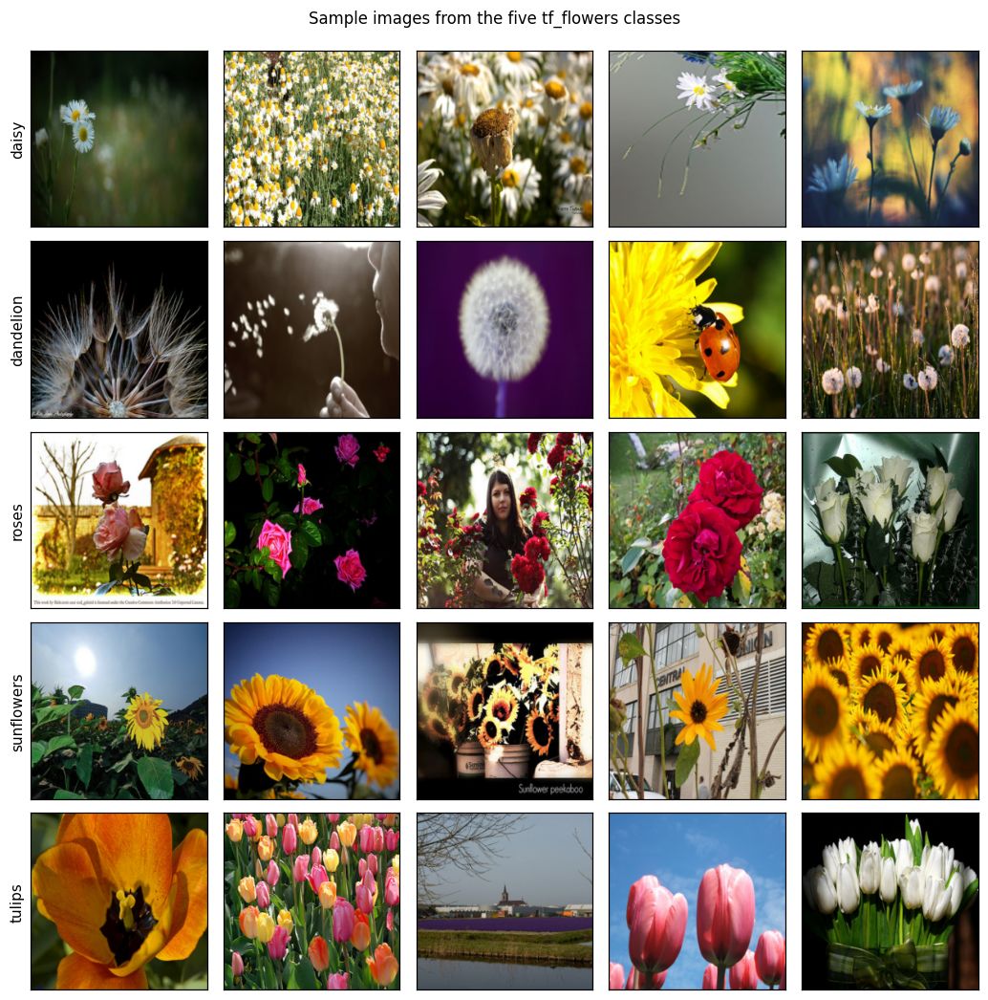

  saved -> lab8_outputs\figures\F01_sample_images.eps


In [4]:
# ===================== DATASET: tf_flowers (5 classes) =====================
FLOWERS_URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'

def ensure_dataset():
    root = DATA_DIR / 'flower_photos'
    if root.exists():
        return root
    tgz = DATA_DIR / 'flower_photos.tgz'
    if not tgz.exists():
        print('Downloading tf_flowers (~218 MB) ...')
        try:
            urllib.request.urlretrieve(FLOWERS_URL, tgz)
        except Exception as e:
            raise RuntimeError(f'Download failed ({e}). Download {FLOWERS_URL} manually and put the extracted '
                               f'"flower_photos" folder inside "{DATA_DIR}/".')
    print('Extracting ...')
    with tarfile.open(tgz) as t:
        try: t.extractall(DATA_DIR, filter='data')
        except TypeError: t.extractall(DATA_DIR)
    return root

root = ensure_dataset()
CLASSES = sorted(d.name for d in root.iterdir() if d.is_dir())
N_CLASSES = len(CLASSES)

paths, labels = [], []
for ci, c in enumerate(CLASSES):
    ps = sorted(p for p in (root / c).iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    if QUICK_TEST: ps = ps[:QUICK_PER_CLASS]
    paths += ps; labels += [ci] * len(ps)
y_all = np.array(labels)

def _load(p):
    with Image.open(p) as im:
        return np.asarray(im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

cache = DATA_DIR / f'flowers_{IMG_SIZE}.npz'
X_all = None
if (not QUICK_TEST) and cache.exists():
    X_all = np.load(cache)['X']
    if len(X_all) != len(paths): X_all = None
if X_all is None:
    print(f'Loading + resizing {len(paths)} images to {IMG_SIZE}x{IMG_SIZE} ...')
    with ThreadPoolExecutor(8) as ex:
        X_all = np.stack(list(ex.map(_load, paths)))
    if not QUICK_TEST: np.savez(cache, X=X_all)
print('Images:', X_all.shape, '| classes:', CLASSES)

# ---------------- fixed stratified 70 : 15 : 15 split (same for every experiment) ----------------
idx_all = np.arange(len(y_all))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=y_all, random_state=SEED)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)
np.savez(RES_DIR / 'split_indices.npz', train=idx_tr, val=idx_va, test=idx_te)

def to_t(X, idx): return torch.from_numpy(X[idx]).permute(0, 3, 1, 2).contiguous()   # uint8 NCHW
Xtr, Xva, Xte = to_t(X_all, idx_tr), to_t(X_all, idx_va), to_t(X_all, idx_te)
ytr, yva, yte = (torch.from_numpy(y_all[i]).long() for i in (idx_tr, idx_va, idx_te))
y_te_np = yte.numpy()
print(f'Train {len(Xtr)} | Val {len(Xva)} | Test {len(Xte)}')

# ---------------- Table: dataset split ----------------
df_split = pd.DataFrame({'Class': CLASSES,
    'Train': [int((ytr == c).sum()) for c in range(N_CLASSES)],
    'Validation': [int((yva == c).sum()) for c in range(N_CLASSES)],
    'Test': [int((yte == c).sum()) for c in range(N_CLASSES)]})
df_split['Total'] = df_split[['Train', 'Validation', 'Test']].sum(axis=1)
df_split.loc[len(df_split)] = ['Total', *df_split[['Train', 'Validation', 'Test', 'Total']].sum().tolist()]
save_table(df_split, 'T00_dataset_split', 'Dataset split (70:15:15, stratified, fixed seed)')

# ---------------- Figure: sample images from all 5 classes ----------------
rng_s = np.random.RandomState(SEED)
n_show = 5
fig, axes = plt.subplots(N_CLASSES, n_show, figsize=(1.9 * n_show, 1.9 * N_CLASSES))
for c in range(N_CLASSES):
    cand = np.where(ytr.numpy() == c)[0]
    pick = rng_s.choice(cand, min(n_show, len(cand)), replace=False)
    for j in range(n_show):
        ax = axes[c, j]; ax.set_xticks([]); ax.set_yticks([])
        if j < len(pick): ax.imshow(Xtr[pick[j]].permute(1, 2, 0).numpy())
        else: ax.axis('off')
        if j == 0: ax.set_ylabel(CLASSES[c], fontsize=10)
fig.suptitle('Sample images from the five tf_flowers classes', y=0.995)
plt.tight_layout()
save_fig(fig, 'F01_sample_images')

In [5]:
# ============ GPU augmentation (identical random stream for every model) ============
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)   # ImageNet statistics
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def normalize(x):                      # x in [0,1], on DEVICE
    return (x - MEAN) / STD

def augment(x, gen):
    """random horizontal flip, rotation (+-10 deg), zoom (+-15 %), translation (+-10 %), mild contrast."""
    B = x.shape[0]
    r = lambda lo, hi: torch.rand(B, generator=gen) * (hi - lo) + lo       # CPU generator -> reproducible
    flip = (torch.rand(B, generator=gen) < 0.5).float() * 2 - 1
    ang, zoom = r(-0.17, 0.17), r(0.85, 1.15)
    tx, ty, con = r(-0.2, 0.2), r(-0.2, 0.2), r(0.8, 1.2)
    c, s = torch.cos(ang) * zoom, torch.sin(ang) * zoom
    theta = torch.stack([torch.stack([c * flip, -s, tx], 1), torch.stack([s * flip, c, ty], 1)], 1).to(x.device)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode='bilinear', padding_mode='reflection', align_corners=False)
    m = x.mean((1, 2, 3), keepdim=True)
    return ((x - m) * con.view(B, 1, 1, 1).to(x.device) + m).clamp_(0, 1)

def batches(X, y, bs, shuffle, gen=None):
    order = torch.randperm(len(X), generator=gen) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), bs):
        idx = order[i:i + bs]
        yield X[idx], y[idx]

def ac():
    return torch.autocast('cuda', dtype=torch.float16) if AMP else contextlib.nullcontext()

def make_scaler():
    try:    return torch.amp.GradScaler('cuda', enabled=AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=AMP)

In [6]:
# ============================ ATTENTION MODULES ============================
# Every module keeps input/output shape (B,C,H,W) unchanged.
# `store=True` makes a module keep its internal attention tensor in `.last` (used for visualisation).

def init_gate_(layer, bias=GATE_BIAS):
    if layer.bias is not None: nn.init.constant_(layer.bias, bias)

class ChannelAttention(nn.Module):
    """M_c(F) = sigmoid(W2 ReLU(W1 GAP(F)))  (the lab's channel attention == SE block).
       use_max=True -> CBAM channel branch (avg- and max-pooled descriptors through a shared MLP)."""
    def __init__(self, C, r=REDUCTION, use_max=False):
        super().__init__()
        h = max(C // r, 4)
        self.fc1, self.fc2, self.use_max = nn.Linear(C, h), nn.Linear(h, C), use_max
        init_gate_(self.fc2, GATE_BIAS / (2 if use_max else 1))
        self.store, self.last = False, None
    def forward(self, x):
        w = self.fc2(F.relu(self.fc1(x.mean((2, 3)))))
        if self.use_max: w = w + self.fc2(F.relu(self.fc1(x.amax((2, 3)))))
        w = torch.sigmoid(w)
        if self.store: self.last = w.detach().float().cpu()
        return x * w[:, :, None, None]

class SpatialAttention(nn.Module):
    """M_s(F) = sigmoid(Conv_kxk([Mean_c(F) || Max_c(F)]))"""
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2)
        init_gate_(self.conv)
        self.store, self.last = False, None
    def forward(self, x):
        m = torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        if self.store: self.last = m.detach().float().cpu()
        return x * m

class SelfAttention2d(nn.Module):
    """Lightweight self-attention: A = softmax(QK^T/sqrt(d)), F_SA = F + gamma * reshape(A V)."""
    def __init__(self, C, r=8):
        super().__init__()
        dk, dv = max(C // r, 8), C // 2
        self.q, self.k = nn.Conv2d(C, dk, 1), nn.Conv2d(C, dk, 1)
        self.v, self.o = nn.Conv2d(C, dv, 1), nn.Conv2d(dv, C, 1)
        self.gamma = nn.Parameter(torch.zeros(1))
        self.scale = dk ** -0.5
        self.store, self.last_attn, self.last_resp = False, None, None
    def forward(self, x):
        B, C, H, W = x.shape
        q = self.q(x).flatten(2).transpose(1, 2)            # B,N,dk
        k = self.k(x).flatten(2)                            # B,dk,N
        v = self.v(x).flatten(2).transpose(1, 2)            # B,N,dv
        a = torch.softmax((q @ k) * self.scale, dim=-1)     # B,N,N   (N = H*W)
        y = self.o((a @ v).transpose(1, 2).reshape(B, -1, H, W))
        if self.store:
            self.last_attn = a.detach().float().cpu()
            self.last_resp = (self.gamma * y).detach().float().cpu()
        return x + self.gamma * y

class ECA(nn.Module):
    """Efficient Channel Attention: GAP -> 1-D conv (adaptive odd kernel k) -> sigmoid."""
    def __init__(self, C, gamma=2, b=1):
        super().__init__()
        t = int(abs((math.log2(C) + b) / gamma)); self.k = t if t % 2 else t + 1
        self.conv = nn.Conv1d(1, 1, self.k, padding=self.k // 2)
        init_gate_(self.conv)
        self.store, self.last = False, None
    def forward(self, x):
        w = torch.sigmoid(self.conv(x.mean((2, 3)).unsqueeze(1))).squeeze(1)
        if self.store: self.last = w.detach().float().cpu()
        return x * w[:, :, None, None]

class CBAM(nn.Module):
    """Convolutional Block Attention Module: channel(avg+max) -> spatial(k x k)."""
    def __init__(self, C, k=7):
        super().__init__()
        self.ca, self.sa = ChannelAttention(C, use_max=True), SpatialAttention(k)
    def forward(self, x): return self.sa(self.ca(x))

class CoordAtt(nn.Module):
    """Coordinate Attention (Hou et al., 2021)."""
    def __init__(self, C, r=32):
        super().__init__()
        mip = max(8, C // r)
        self.conv1, self.bn1, self.act = nn.Conv2d(C, mip, 1), nn.BatchNorm2d(mip), nn.Hardswish()
        self.conv_h, self.conv_w = nn.Conv2d(mip, C, 1), nn.Conv2d(mip, C, 1)
        init_gate_(self.conv_h); init_gate_(self.conv_w)
    def forward(self, x):
        B, C, H, W = x.shape
        y = torch.cat([x.mean(3, keepdim=True), x.mean(2, keepdim=True).permute(0, 1, 3, 2)], dim=2)
        y = self.act(self.bn1(self.conv1(y)))
        yh, yw = torch.split(y, [H, W], dim=2)
        ah = torch.sigmoid(self.conv_h(yh))
        aw = torch.sigmoid(self.conv_w(yw.permute(0, 1, 3, 2)))
        return x * aw * ah

def make_block(kind, C, k=7):
    mods = {
        'channel':  lambda: [ChannelAttention(C)],
        'spatial':  lambda: [SpatialAttention(k)],
        'cs':       lambda: [ChannelAttention(C), SpatialAttention(k)],          # Channel -> Spatial
        'sc':       lambda: [SpatialAttention(k), ChannelAttention(C)],          # Spatial -> Channel
        'self':     lambda: [SelfAttention2d(C)],
        'combined': lambda: [ChannelAttention(C), SpatialAttention(k), SelfAttention2d(C)],
        'eca':      lambda: [ECA(C)],
        'cbam':     lambda: [CBAM(C, k)],
        'coord':    lambda: [CoordAtt(C)],
    }[kind]()
    return nn.Sequential(*mods)

def find_modules(block, cls):
    return [m for m in block.modules() if isinstance(m, cls)]

In [7]:
# ================== ResNet50 + attention at P1..P4 + experiment registry ==================
STAGE_CH   = {'P1': 256, 'P2': 512, 'P3': 1024, 'P4': 2048}
STAGE_NAME = {'P1': 'conv2_x', 'P2': 'conv3_x', 'P3': 'conv4_x', 'P4': 'conv5_x'}

class AttnResNet50(nn.Module):
    """ImageNet ResNet50 -> [attention after chosen stages] -> GAP -> Dropout -> Dense(5)."""
    def __init__(self, attn_spec, n_classes=5, pretrained=True, dropout=0.3):
        super().__init__()
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        r = torchvision.models.resnet50(weights=w)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        self.attn = nn.ModuleDict({p: make_block(kind, STAGE_CH[p], **kw) for p, (kind, kw) in attn_spec.items()})
        self.pool, self.drop, self.fc = nn.AdaptiveAvgPool2d(1), nn.Dropout(dropout), nn.Linear(2048, n_classes)
        self.record, self.cache = False, {}

    def backbone_modules(self):
        return [self.stem, self.layer1, self.layer2, self.layer3, self.layer4]

    def forward_features(self, x):
        x = self.stem(x)
        for i, layer in enumerate([self.layer1, self.layer2, self.layer3, self.layer4], start=1):
            x = layer(x)
            key = f'P{i}'
            if key in self.attn:
                if self.record: self.cache[key + '_before'] = x.detach().float().cpu()
                x = self.attn[key](x)
                if self.record: self.cache[key + '_after'] = x.detach().float().cpu()
        return x

    def head(self, f):
        return self.fc(self.drop(self.pool(f).flatten(1)))

    def forward(self, x):
        return self.head(self.forward_features(x))

    def train(self, mode=True):                 # pretrained BatchNorm statistics are never updated
        super().train(mode)
        for m in self.backbone_modules():
            for mod in m.modules():
                if isinstance(mod, nn.BatchNorm2d): mod.eval()
        return self

    def set_phase(self, phase):
        """'head': only attention + classifier train.  'ft': + conv5_x (layer4) conv weights."""
        for p in self.parameters(): p.requires_grad = False
        for p in list(self.attn.parameters()) + list(self.fc.parameters()): p.requires_grad = True
        if phase == 'ft':
            for m in self.layer4.modules():
                if isinstance(m, nn.Conv2d):
                    for p in m.parameters(): p.requires_grad = True

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    attn = sum(p.numel() for p in model.attn.parameters())
    return total, trainable, attn

# ---------------- experiment registry (insertion order == run order) ----------------
def E(i, label, pos, **attn): return dict(id=i, label=label, pos=pos, attn=attn)
EXPERIMENTS = {
 'A0_Baseline':      E('A0', 'Baseline ResNet50',         '--'),
 'A1_Channel_P3':    E('A1', 'Channel / SE',              'P3', P3=('channel', {})),
 'A2_Spatial_P3':    E('A2', 'Spatial (k=7)',             'P3', P3=('spatial', dict(k=7))),
 'A3_ChSp_P3':       E('A3', 'Channel->Spatial',          'P3', P3=('cs', dict(k=7))),
 'A4_Self_P3':       E('A4', 'Self-Attention',            'P3', P3=('self', {})),
 'B2_ChSp_P2':       E('B2', 'Channel->Spatial',          'P2', P2=('cs', dict(k=7))),
 'B4_ChSp_P4':       E('B4', 'Channel->Spatial',          'P4', P4=('cs', dict(k=7))),
 'A5_Combined_P3':   E('A5', 'Channel+Spatial+Self',      'P3', P3=('combined', dict(k=7))),
 'X1_ECA_P3':        E('X1', 'ECA',                       'P3', P3=('eca', {})),
 'X2_CBAM_P3':       E('X2', 'CBAM',                      'P3', P3=('cbam', dict(k=7))),
 'X3_CoordAtt_P3':   E('X3', 'Coordinate Attention',      'P3', P3=('coord', {})),
 'B1_ChSp_P1':       E('B1', 'Channel->Spatial',          'P1', P1=('cs', dict(k=7))),
 'M1_ChSp_P3P4':     E('M1', 'Channel->Spatial',          'P3+P4', P3=('cs', dict(k=7)), P4=('cs', dict(k=7))),
 'M2_ChSp_P2P3P4':   E('M2', 'Channel->Spatial',          'P2+P3+P4', P2=('cs', dict(k=7)), P3=('cs', dict(k=7)), P4=('cs', dict(k=7))),
 'O1_SpCh_P3':       E('O1', 'Spatial->Channel',          'P3', P3=('sc', dict(k=7))),
 'K3_Spatial_P3':    E('K3', 'Spatial (k=3)',             'P3', P3=('spatial', dict(k=3))),
 'K5_Spatial_P3':    E('K5', 'Spatial (k=5)',             'P3', P3=('spatial', dict(k=5))),
}
print(len(EXPERIMENTS), 'experiments:', ', '.join(v['id'] for v in EXPERIMENTS.values()))

17 experiments: A0, A1, A2, A3, A4, B2, B4, A5, X1, X2, X3, B1, M1, M2, O1, K3, K5


In [8]:
# ====================== TRAINING / EVALUATION / TIMING ======================
def make_optimizer(model, lr):
    gam  = [p for n, p in model.named_parameters() if p.requires_grad and n.endswith('gamma')]
    rest = [p for n, p in model.named_parameters() if p.requires_grad and not n.endswith('gamma')]
    groups = [{'params': rest, 'lr': lr}]
    if gam: groups.append({'params': gam, 'lr': lr * GAMMA_LR_MULT})
    return torch.optim.Adam(groups)

def train_step(model, opt, scaler, xb, yb, gen, sched=None):
    xb = xb.to(DEVICE, non_blocking=True).float().div_(255.0)
    xb = normalize(augment(xb, gen)).contiguous(memory_format=torch.channels_last)
    yb = yb.to(DEVICE, non_blocking=True)
    with ac():
        logits = model(xb)
    loss = F.cross_entropy(logits.float(), yb)                    # categorical cross-entropy
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    if sched is not None: sched.step()
    return loss.detach(), (logits.argmax(1) == yb).sum()

@torch.no_grad()
def predict(model, X, bs=128):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = normalize(X[i:i + bs].to(DEVICE).float().div_(255.0)).contiguous(memory_format=torch.channels_last)
        with ac():
            out.append(model(xb).float().cpu())
    return torch.cat(out)

def evaluate(model, X, y):
    lg = predict(model, X)
    return F.cross_entropy(lg, y).item(), (lg.argmax(1) == y).float().mean().item(), lg

@torch.no_grad()
def measure_inference(model, bs=1, n_warm=20, n_runs=100):
    """mean wall-clock time per image (ms)."""
    model.eval()
    x = torch.randn(bs, 3, IMG_SIZE, IMG_SIZE, device=DEVICE).contiguous(memory_format=torch.channels_last)
    for _ in range(n_warm):
        with ac(): model(x)
    ts = []
    for _ in range(n_runs):
        sync(); t = time.perf_counter()
        with ac(): model(x)
        sync(); ts.append(time.perf_counter() - t)
    return float(np.mean(ts) * 1000 / bs)

def compute_metrics(y_true, y_pred):
    labs = list(range(N_CLASSES))
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labs, average='macro', zero_division=0)
    pc, rc, fc, sc = precision_recall_fscore_support(y_true, y_pred, labels=labs, average=None, zero_division=0)
    return dict(acc=float((y_true == y_pred).mean()), precision=float(p), recall=float(r), f1=float(f),
                per_class=dict(precision=pc.tolist(), recall=rc.tolist(), f1=fc.tolist(), support=sc.tolist()),
                cm=confusion_matrix(y_true, y_pred, labels=labs).tolist())

def run_experiment(name, spec, tag=''):
    seed_everything(SEED)
    model = AttnResNet50(spec['attn'], N_CLASSES, PRETRAINED, DROPOUT).to(DEVICE).to(memory_format=torch.channels_last)
    hist = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'phase', 'lr')}
    scaler, steps_ep = make_scaler(), math.ceil(len(Xtr) / BATCH_SIZE)
    t0, g_ep = time.time(), 0
    for phase, n_ep, lr in (('head', EPOCHS_HEAD, LR_HEAD), ('ft', EPOCHS_FT, LR_FT)):
        model.set_phase(phase)
        opt = make_optimizer(model, lr)
        total = n_ep * steps_ep
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, lambda s, total=total: 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
        for ep in range(n_ep):
            te = time.time(); model.train()
            gen = torch.Generator().manual_seed(SEED * 1000 + g_ep); g_ep += 1
            ls, cs, n = torch.zeros((), device=DEVICE), torch.zeros((), device=DEVICE), 0
            for xb, yb in batches(Xtr, ytr, BATCH_SIZE, True, gen):
                l, c = train_step(model, opt, scaler, xb, yb, gen, sched)
                ls += l * len(xb); cs += c; n += len(xb)
            tr_loss, tr_acc = ls.item() / n, cs.item() / n
            va_loss, va_acc, _ = evaluate(model, Xva, yva)
            for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc, phase, opt.param_groups[0]['lr'])): hist[k].append(v)
            print(f'  {tag}{name} | {phase:4s} ep {ep + 1}/{n_ep} | train {tr_loss:.4f}/{tr_acc:.4f} '
                  f'| val {va_loss:.4f}/{va_acc:.4f} | {time.time() - te:.1f}s', flush=True)
    train_time = time.time() - t0

    # ---- final evaluation ----
    model.set_phase('ft')
    n_total, n_train, n_attn = count_params(model)
    trc_loss, trc_acc, _ = evaluate(model, Xtr, ytr)                  # clean (no augmentation) training metrics
    te_loss, te_acc, te_logits = evaluate(model, Xte, yte)
    preds = te_logits.argmax(1).numpy()
    probs = te_logits.softmax(1).max(1).values.numpy()
    met = compute_metrics(y_te_np, preds); met['loss'] = te_loss
    inf1  = measure_inference(model, 1, 20, TIMING_RUNS)
    inf32 = measure_inference(model, 32, 5, max(5, TIMING_RUNS // 4)) if not QUICK_TEST else measure_inference(model, 8, 2, 5)
    sd = {k: v.cpu() for k, v in model.state_dict().items() if k.startswith(('attn.', 'layer4.', 'fc.'))}
    torch.save(sd, CKPT_DIR / f'{name}.pt')
    res = dict(name=name, id=spec['id'], label=spec['label'], pos=spec['pos'],
               epochs_head=EPOCHS_HEAD, epochs_ft=EPOCHS_FT, hist=hist, test=met,
               train_clean=dict(loss=trc_loss, acc=trc_acc), preds=preds.tolist(), conf=probs.tolist(),
               params_total=n_total, params_trainable=n_train, params_attn=n_attn,
               inf_ms_bs1=inf1, inf_ms_bs32=inf32, train_time_s=train_time)
    del model, opt; gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return res

In [9]:
# ============== Pick the (minimal) number of epochs that fits TARGET_HOURS ==============
existing = sorted(RES_DIR.glob('A*.json')) + sorted(RES_DIR.glob('[B-Z]*.json'))
existing = [p for p in existing if p.stem in EXPERIMENTS]

def benchmark(n_warm=3, n_meas=8):
    seed_everything(SEED)
    m = AttnResNet50({}, N_CLASSES, PRETRAINED, DROPOUT).to(DEVICE).to(memory_format=torch.channels_last)
    gen, out, scaler = torch.Generator().manual_seed(0), {}, make_scaler()
    for phase in ('head', 'ft'):
        m.set_phase(phase); m.train(); opt = make_optimizer(m, 1e-4); ts = []
        for i, (xb, yb) in enumerate(batches(Xtr, ytr, BATCH_SIZE, True, gen)):
            if i >= n_warm + n_meas: break
            sync(); t = time.perf_counter()
            train_step(m, opt, scaler, xb, yb, gen); sync()
            if i >= n_warm: ts.append(time.perf_counter() - t)
        out[phase] = float(np.median(ts))
    nv = min(len(Xva), 256); sync(); t = time.perf_counter()
    predict(m, Xva[:nv]); sync()
    out['val'] = (time.perf_counter() - t) * len(Xva) / nv
    out['lat1'] = measure_inference(m, 1, 3, 10) / 1000
    del m, opt; gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return out

def estimate_seconds(eh, ef, b, n_models):
    steps = math.ceil(len(Xtr) / BATCH_SIZE)
    per = (eh * (steps * b['head'] + b['val']) + ef * (steps * b['ft'] + b['val'])) * ATTN_OVERHEAD
    per += b['val'] * (1 + len(Xtr) / max(len(Xva), 1) + len(Xte) / max(len(Xva), 1)) + (TIMING_RUNS + 20) * b['lat1'] * 1.5 + 8
    return per * n_models

if existing:                                   # resuming -> keep the protocol identical to finished runs
    r0 = json.load(open(existing[0]))
    EPOCHS_HEAD, EPOCHS_FT = r0['epochs_head'], r0['epochs_ft']
    print(f'Resuming: {len(existing)} finished experiment(s) found -> keeping epochs = {EPOCHS_HEAD} (head) + {EPOCHS_FT} (fine-tune)')
elif EPOCHS_HEAD is None or EPOCHS_FT is None:
    print('Benchmarking this machine (about 1 minute) ...')
    bench = benchmark()
    print({k: round(v, 4) for k, v in bench.items()})
    budget = TARGET_HOURS * 3600 - VIZ_RESERVE_MIN * 60
    chosen = None
    for eh, ef in EPOCH_CANDIDATES:
        est = estimate_seconds(eh, ef, bench, len(EXPERIMENTS))
        if est <= budget: chosen = (eh, ef, est); break
    if chosen is None:
        eh, ef = EPOCH_CANDIDATES[-1]; chosen = (eh, ef, estimate_seconds(eh, ef, bench, len(EXPERIMENTS)))
        print(f'WARNING: even {eh}+{ef} epochs is estimated to exceed the budget. Consider a GPU, or a smaller TARGET.')
    EPOCHS_HEAD, EPOCHS_FT, est = chosen
    print(f'Chosen epochs: {EPOCHS_HEAD} (frozen backbone) + {EPOCHS_FT} (fine-tune conv5_x)  '
          f'-> estimated training time for {len(EXPERIMENTS)} models: {est / 3600:.2f} h')
else:
    print(f'Using manual epochs: {EPOCHS_HEAD} + {EPOCHS_FT}')

Benchmarking this machine (about 1 minute) ...
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to C:\Users\satha/.cache\torch\hub\checkpoints\resnet50-0676ba61.pth


100%|█████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [00:03<00:00, 32.4MB/s]


{'head': 0.0347, 'ft': 0.0436, 'val': 44.0629, 'lat1': 0.0265}
Chosen epochs: 1 (frozen backbone) + 1 (fine-tune conv5_x)  -> estimated training time for 17 models: 2.01 h


In [10]:
# ======================= RUN ALL EXPERIMENTS (resumable) =======================
t_start, n_exp, done_times = time.time(), len(EXPERIMENTS), []
for i, (name, spec) in enumerate(EXPERIMENTS.items(), 1):
    f = RES_DIR / f'{name}.json'
    if f.exists():
        print(f'[{i}/{n_exp}] {name}: already finished -> skipped'); continue
    print(f'\n=== [{i}/{n_exp}] {name}  ({spec["label"]}, position {spec["pos"]}) ===')
    t = time.time()
    res = run_experiment(name, spec, tag=f'[{i}/{n_exp}] ')
    json.dump(res, open(f, 'w'))
    done_times.append(time.time() - t)
    left = n_exp - i
    t_ = res['test']
    print(f'  -> TEST acc {t_["acc"]*100:.2f}% | macro-F1 {t_["f1"]*100:.2f}% | params {res["params_total"]/1e6:.3f}M '
          f'| {res["inf_ms_bs1"]:.2f} ms/img | model time {done_times[-1]/60:.1f} min '
          f'| elapsed {(time.time()-t_start)/60:.1f} min | ETA ~{np.mean(done_times)*left/60:.1f} min')
print(f'\nAll {n_exp} experiments finished. Total time this session: {(time.time() - t_start) / 60:.1f} min')


=== [1/17] A0_Baseline  (Baseline ResNet50, position --) ===
  [1/17] A0_Baseline | head ep 1/1 | train 0.8309/0.7197 | val 0.5915/0.8145 | 41.7s
  [1/17] A0_Baseline | ft   ep 1/1 | train 0.3669/0.8708 | val 0.2468/0.9127 | 20.9s
  -> TEST acc 93.28% | macro-F1 93.37% | params 23.518M | 22.37 ms/img | model time 1.5 min | elapsed 1.5 min | ETA ~23.7 min

=== [2/17] A1_Channel_P3  (Channel / SE, position P3) ===
  [2/17] A1_Channel_P3 | head ep 1/1 | train 0.8144/0.7287 | val 0.5712/0.8291 | 3.8s
  [2/17] A1_Channel_P3 | ft   ep 1/1 | train 0.3806/0.8696 | val 0.2417/0.9218 | 4.1s
  -> TEST acc 92.38% | macro-F1 92.47% | params 23.650M | 19.76 ms/img | model time 0.3 min | elapsed 1.7 min | ETA ~13.0 min

=== [3/17] A2_Spatial_P3  (Spatial (k=7), position P3) ===
  [3/17] A2_Spatial_P3 | head ep 1/1 | train 0.8126/0.7155 | val 0.5807/0.8236 | 8.9s
  [3/17] A2_Spatial_P3 | ft   ep 1/1 | train 0.3745/0.8661 | val 0.2402/0.9200 | 4.1s
  -> TEST acc 92.38% | macro-F1 92.42% | params 23.51

In [11]:
# ============================== ALL TABLES ==============================
R = {n: json.load(open(RES_DIR / f'{n}.json')) for n in EXPERIMENTS if (RES_DIR / f'{n}.json').exists()}
missing = [n for n in EXPERIMENTS if n not in R]
assert not missing, f'Finish training first, missing: {missing}'
EH, EF = R['A0_Baseline']['epochs_head'], R['A0_Baseline']['epochs_ft']

def row(name, model=None, pos=None, extra=None):
    r = R[name]; t = r['test']
    d = {'Model': model or f"{r['id']}: {r['label']}", 'Position': pos or r['pos'],
         'Accuracy (%)': 100 * t['acc'], 'Precision (%)': 100 * t['precision'], 'Recall (%)': 100 * t['recall'],
         'Macro F1 (%)': 100 * t['f1'], 'Params (M)': r['params_total'] / 1e6,
         'Inference (ms/img)': r['inf_ms_bs1']}
    if extra: d.update(extra)
    return d

# ---- T01: measured ResNet50 stage dimensions ----
_m = AttnResNet50({}, N_CLASSES, False).eval(); _x = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)
rows = [('Input', tuple(_x.shape[1:]))]
with torch.no_grad():
    _x = _m.stem(_x); rows.append(('Stem + MaxPool', tuple(_x.shape[1:])))
    for nm, l in zip(['conv2_x (P1)', 'conv3_x (P2)', 'conv4_x (P3)', 'conv5_x (P4)'],
                     [_m.layer1, _m.layer2, _m.layer3, _m.layer4]):
        _x = l(_x); rows.append((nm, tuple(_x.shape[1:])))
df_dims = pd.DataFrame({'ResNet50 stage': [r[0] for r in rows],
                        'Resolution': [f'{r[1][1]}x{r[1][2]}' if len(r[1]) == 3 else '' for r in rows],
                        'Channels': [r[1][0] for r in rows],
                        'Tensor (C,H,W)': [str(r[1]) for r in rows]})
save_table(df_dims, 'T01_resnet50_stage_dimensions', 'Measured ResNet50 stage output dimensions')

# ---- T02: feature dimensions immediately before / after the attention block (Sec. 13) ----
rows = []
for p in ('P1', 'P2', 'P3', 'P4'):
    mm = AttnResNet50({p: ('cs', dict(k=7))}, N_CLASSES, False).eval(); mm.record = True
    with torch.no_grad(): mm(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE))
    b, a = tuple(mm.cache[p + '_before'].shape[1:]), tuple(mm.cache[p + '_after'].shape[1:])
    rows.append({'Position': p, 'Location': f'after {STAGE_NAME[p]}', 'Before attention (C,H,W)': str(b),
                 'After attention (C,H,W)': str(a), 'Shape preserved': 'yes' if a == b else 'NO',
                 'Channel->Spatial params (K)': sum(q.numel() for q in mm.attn.parameters()) / 1e3})
df_pos_dims = pd.DataFrame(rows)
save_table(df_pos_dims, 'T02_attention_position_dimensions', 'Feature dimensions before and after the attention block')

# ---- T03: Experiment 1 - attention type ablation (fixed position P3) ----
ticks = {'A0': ('--', '--', '--'), 'A1': ('yes', '--', '--'), 'A2': ('--', 'yes', '--'),
         'A3': ('yes', 'yes', '--'), 'A4': ('--', '--', 'yes'), 'A5': ('yes', 'yes', 'yes')}
rows = []
for n in ['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3', 'A5_Combined_P3']:
    r = R[n]; c, s, a = ticks[r['id']]
    rows.append(row(n, extra={'Channel': c, 'Spatial': s, 'Self-Attn': a,
                              'Trainable (M)': r['params_trainable'] / 1e6, 'Attn params (K)': r['params_attn'] / 1e3}))
df_exp1 = pd.DataFrame(rows)
save_table(df_exp1, 'T03_exp1_attention_type_ablation', 'Experiment 1: attention-type ablation at P3 (test set)')

# ---- T04: Experiment 2 - attention position ablation (Channel->Spatial) ----
res_ch = {'P1': ('56x56', 256), 'P2': ('28x28', 512), 'P3': ('14x14', 1024), 'P4': ('7x7', 2048)}
rows = []
for bid, n, p in [('B1', 'B1_ChSp_P1', 'P1'), ('B2', 'B2_ChSp_P2', 'P2'), ('B3', 'A3_ChSp_P3', 'P3'), ('B4', 'B4_ChSp_P4', 'P4')]:
    r = R[n]
    rows.append(row(n, model=f'{bid}: Channel->Spatial after {STAGE_NAME[p]}', extra={
        'Resolution': res_ch[p][0], 'Channels': res_ch[p][1], 'Attn params (K)': r['params_attn'] / 1e3,
        'Trainable (M)': r['params_trainable'] / 1e6}))
rows.insert(0, row('A0_Baseline', model='Baseline (no attention)', extra={'Resolution': '--', 'Channels': '--',
            'Attn params (K)': 0.0, 'Trainable (M)': R['A0_Baseline']['params_trainable'] / 1e6}))
df_exp2 = pd.DataFrame(rows)
save_table(df_exp2, 'T04_exp2_attention_position_ablation', 'Experiment 2: attention-position ablation, Channel->Spatial (test set)')

# ---- T05: Experiment 3 - multiple attention positions ----
rows = [row('A0_Baseline', model='Baseline (no attention)'),
        row('A3_ChSp_P3', model='Attention only at P3'), row('B4_ChSp_P4', model='Attention only at P4'),
        row('M1_ChSp_P3P4', model='Attention at P3+P4'), row('M2_ChSp_P2P3P4', model='Attention at P2+P3+P4 (extended)')]
for rw, n in zip(rows, ['A0_Baseline', 'A3_ChSp_P3', 'B4_ChSp_P4', 'M1_ChSp_P3P4', 'M2_ChSp_P2P3P4']):
    r = R[n]; rw.update({'Attn params (K)': r['params_attn'] / 1e3, 'Train time (min)': r['train_time_s'] / 60,
                         'Inference bs32 (ms/img)': r['inf_ms_bs32']})
df_exp3 = pd.DataFrame(rows)
save_table(df_exp3, 'T05_exp3_multiple_positions', 'Experiment 3: single vs multiple attention positions (test set)')

# ---- T06: Experiment 4 - attention order (position P3) ----
df_exp4 = pd.DataFrame([row('A3_ChSp_P3', model='Channel->Spatial'), row('O1_SpCh_P3', model='Spatial->Channel')])
save_table(df_exp4, 'T06_exp4_attention_order', 'Experiment 4: attention order at P3 (test set)')

# ---- T07: Experiment 5 - spatial kernel size (spatial-only attention at P3) ----
rows = []
for k, n in [(3, 'K3_Spatial_P3'), (5, 'K5_Spatial_P3'), (7, 'A2_Spatial_P3')]:
    r = R[n]; t = r['test']
    rows.append({'Spatial kernel': f'{k}x{k}', 'Accuracy (%)': 100 * t['acc'], 'Macro F1 (%)': 100 * t['f1'],
                 'Inference (ms/img)': r['inf_ms_bs1'], 'Precision (%)': 100 * t['precision'], 'Recall (%)': 100 * t['recall'],
                 'Attn params': r['params_attn']})
df_exp5 = pd.DataFrame(rows)
save_table(df_exp5, 'T07_exp5_spatial_kernel_size', 'Experiment 5: spatial-attention kernel size at P3 (test set)')

# ---- T08: Sec. 19.1 comparison of attention mechanisms ----
cmp_rows = [('A0_Baseline', 'No Attention'), ('A1_Channel_P3', 'Channel / SE'), ('A2_Spatial_P3', 'Spatial Attention'),
            ('X1_ECA_P3', 'ECA'), ('X2_CBAM_P3', 'CBAM'), ('A4_Self_P3', 'Self-Attention'),
            ('X3_CoordAtt_P3', 'Additional: Coordinate Attention'), ('A3_ChSp_P3', 'Channel->Spatial (lab module)'),
            ('A5_Combined_P3', 'Combined (Ch+Sp+Self)')]
cols19 = ['Model', 'Accuracy (%)', 'Precision (%)', 'Recall (%)', 'Macro F1 (%)', 'Params (M)', 'Inference (ms/img)']
df_cmp = pd.DataFrame([row(n, model=l) for n, l in cmp_rows])[cols19]
save_table(df_cmp, 'T08_comparison_of_attention_mechanisms', 'Comparison of attention mechanisms at P3 (test set)')

# ---- T09: Sec. 23 required main result table ----
main_rows = [('A0_Baseline', 'Baseline', '--'), ('A1_Channel_P3', 'Channel Attention', 'P3'),
             ('A2_Spatial_P3', 'Spatial Attention', 'P3'), ('B2_ChSp_P2', 'Channel+Spatial', 'P2'),
             ('A3_ChSp_P3', 'Channel+Spatial', 'P3'), ('B4_ChSp_P4', 'Channel+Spatial', 'P4'),
             ('A4_Self_P3', 'Self-Attention', 'P3'), ('X1_ECA_P3', 'Additional Attention-1 (ECA)', 'P3'),
             ('X2_CBAM_P3', 'Additional Attention-2 (CBAM)', 'P3'), ('X3_CoordAtt_P3', 'Additional Attention-3 (CoordAtt)', 'P3')]
cols23 = ['Model', 'Position', 'Accuracy (%)', 'Precision (%)', 'Recall (%)', 'Macro F1 (%)', 'Params (M)', 'Inference (ms/img)']
df_main = pd.DataFrame([row(n, model=l, pos=p) for n, l, p in main_rows])[cols23]
save_table(df_main, 'T09_required_main_result_table', 'Main result table (test set)')

# ---- T10: per-class precision / recall / F1 for the main models ----
rows = []
for n, lab in [('A0_Baseline', 'Baseline'), ('A1_Channel_P3', 'Channel'), ('A2_Spatial_P3', 'Spatial'),
               ('A3_ChSp_P3', 'Ch->Sp'), ('A4_Self_P3', 'Self-Att')]:
    pc = R[n]['test']['per_class']
    for c, cn in enumerate(CLASSES):
        rows.append({'Model': lab, 'Class': cn, 'Precision (%)': 100 * pc['precision'][c],
                     'Recall (%)': 100 * pc['recall'][c], 'F1 (%)': 100 * pc['f1'][c], 'Support': pc['support'][c]})
df_pc = pd.DataFrame(rows)
save_table(df_pc, 'T10_classwise_metrics', 'Class-wise precision, recall and F1 (test set)')

# ---- T11: observations (training / validation / test accuracy + loss, convergence) ----
rows = []
for n in EXPERIMENTS:
    r = R[n]; h = r['hist']; best = int(np.argmax(h['val_acc']))
    first90 = next((i + 1 for i, v in enumerate(h['val_acc']) if v >= 0.90), None)
    rows.append({'Model': f"{r['id']}: {r['label']}", 'Position': r['pos'],
                 'Train acc, aug. (%)': 100 * h['train_acc'][-1], 'Train acc, clean (%)': 100 * r['train_clean']['acc'],
                 'Val acc (%)': 100 * h['val_acc'][-1], 'Test acc (%)': 100 * r['test']['acc'],
                 'Train loss': h['train_loss'][-1], 'Val loss': h['val_loss'][-1], 'Test loss': r['test']['loss'],
                 'Clean-train minus test acc (pp)': 100 * (r['train_clean']['acc'] - r['test']['acc']),
                 'Best val epoch': best + 1, 'First epoch val>=90%': first90 if first90 else 'never'})
df_obs = pd.DataFrame(rows)
save_table(df_obs, 'T11_training_observations', 'Training / validation / test observations and convergence')

# ---- T12: complexity ----
rows = []
for n in EXPERIMENTS:
    r = R[n]
    rows.append({'Model': f"{r['id']}: {r['label']}", 'Position': r['pos'],
                 'Total params (M)': r['params_total'] / 1e6, 'Trainable params, fine-tune phase (M)': r['params_trainable'] / 1e6,
                 'Attention params (K)': r['params_attn'] / 1e3, 'Inference bs=1 (ms/img)': r['inf_ms_bs1'],
                 'Inference bs=32 (ms/img)': r['inf_ms_bs32'], 'Training time (min)': r['train_time_s'] / 60})
df_cx = pd.DataFrame(rows)
save_table(df_cx, 'T12_complexity_analysis', 'Complexity: parameters, inference time and training time')

# ---- T13: master table ----
df_master = pd.DataFrame([row(n, extra={'Trainable (M)': R[n]['params_trainable'] / 1e6,
                                        'Attn params (K)': R[n]['params_attn'] / 1e3}) for n in EXPERIMENTS])
save_table(df_master, 'T13_master_all_experiments', 'All 17 experiments (test set)')
print(f'\nEpoch protocol for every model: {EH} epochs (frozen backbone, lr {LR_HEAD}) + {EF} epochs (fine-tune conv5_x, lr {LR_FT}).')


### Measured ResNet50 stage output dimensions   [T01_resnet50_stage_dimensions.csv / T01_resnet50_stage_dimensions.tex]


ResNet50 stage,Resolution,Channels,"Tensor (C,H,W)"
Input,224x224,3,"(3, 224, 224)"
Stem + MaxPool,56x56,64,"(64, 56, 56)"
conv2_x (P1),56x56,256,"(256, 56, 56)"
conv3_x (P2),28x28,512,"(512, 28, 28)"
conv4_x (P3),14x14,1024,"(1024, 14, 14)"
conv5_x (P4),7x7,2048,"(2048, 7, 7)"



### Feature dimensions before and after the attention block   [T02_attention_position_dimensions.csv / T02_attention_position_dimensions.tex]


Position,Location,"Before attention (C,H,W)","After attention (C,H,W)",Shape preserved,Channel->Spatial params (K)
P1,after conv2_x,"(256, 56, 56)","(256, 56, 56)",yes,8.56
P2,after conv3_x,"(512, 28, 28)","(512, 28, 28)",yes,33.41
P3,after conv4_x,"(1024, 14, 14)","(1024, 14, 14)",yes,132.26
P4,after conv5_x,"(2048, 7, 7)","(2048, 7, 7)",yes,526.56



### Experiment 1: attention-type ablation at P3 (test set)   [T03_exp1_attention_type_ablation.csv / T03_exp1_attention_type_ablation.tex]


...


### Complexity: parameters, inference time and training time   [T12_complexity_analysis.csv / T12_complexity_analysis.tex]


Model,Position,Total params (M),"Trainable params, fine-tune phase (M)",Attention params (K),Inference bs=1 (ms/img),Inference bs=32 (ms/img),Training time (min)
A0: Baseline ResNet50,--,23.52,14.95,0.00,22.37,0.92,1.04
A1: Channel / SE,P3,23.65,15.08,132.16,19.76,0.90,0.13
A2: Spatial (k=7),P3,23.52,14.95,0.10,22.41,0.88,0.22
A3: Channel->Spatial,P3,23.65,15.08,132.26,23.44,0.93,0.14
A4: Self-Attention,P3,24.83,16.26,1312.51,22.80,0.93,0.47
B2: Channel->Spatial,P2,23.55,14.99,33.41,23.32,0.94,0.30
B4: Channel->Spatial,P4,24.04,15.48,526.56,22.08,0.93,0.24
A5: Channel+Spatial+Self,P3,24.96,16.40,1444.77,25.24,0.99,0.15
X1: ECA,P3,23.52,14.95,0.01,22.06,0.92,0.21
X2: CBAM,P3,23.65,15.08,132.26,23.99,1.00,0.14



### All 17 experiments (test set)   [T13_master_all_experiments.csv / T13_master_all_experiments.tex]


Model,Position,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Params (M),Inference (ms/img),Trainable (M),Attn params (K)
A0: Baseline ResNet50,--,93.28,93.61,93.34,93.37,23.52,22.37,14.95,0.00
A1: Channel / SE,P3,92.38,92.80,92.35,92.47,23.65,19.76,15.08,132.16
A2: Spatial (k=7),P3,92.38,92.58,92.49,92.42,23.52,22.41,14.95,0.10
A3: Channel->Spatial,P3,92.20,92.50,92.11,92.22,23.65,23.44,15.08,132.26
A4: Self-Attention,P3,92.74,93.06,92.65,92.76,24.83,22.80,16.26,1312.51
B2: Channel->Spatial,P2,92.74,93.04,92.66,92.76,23.55,23.32,14.99,33.41
B4: Channel->Spatial,P4,92.74,93.02,92.72,92.78,24.04,22.08,15.48,526.56
A5: Channel+Spatial+Self,P3,92.20,92.52,92.15,92.20,24.96,25.24,16.40,1444.77
X1: ECA,P3,92.74,92.97,92.63,92.73,23.52,22.06,14.95,0.01
X2: CBAM,P3,92.38,92.67,92.42,92.34,23.65,23.99,15.08,132.26



Epoch protocol for every model: 1 epochs (frozen backbone, lr 0.001) + 1 epochs (fine-tune conv5_x, lr 0.0001).


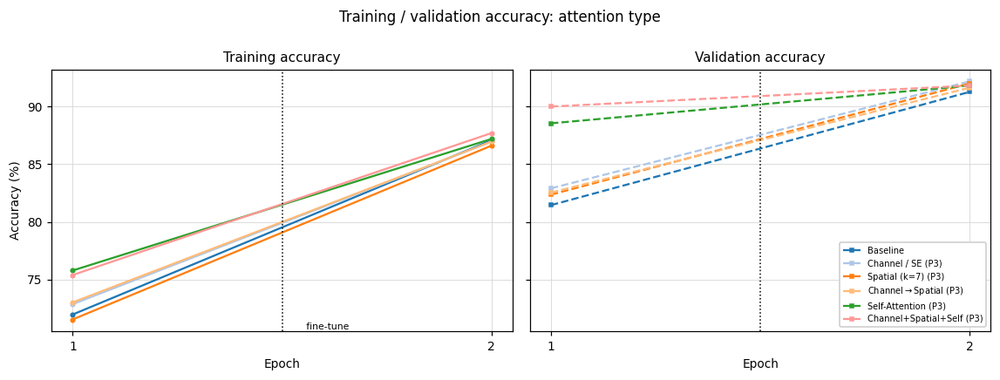

  saved -> lab8_outputs\figures\F02_accuracy_curves_attention_type.eps


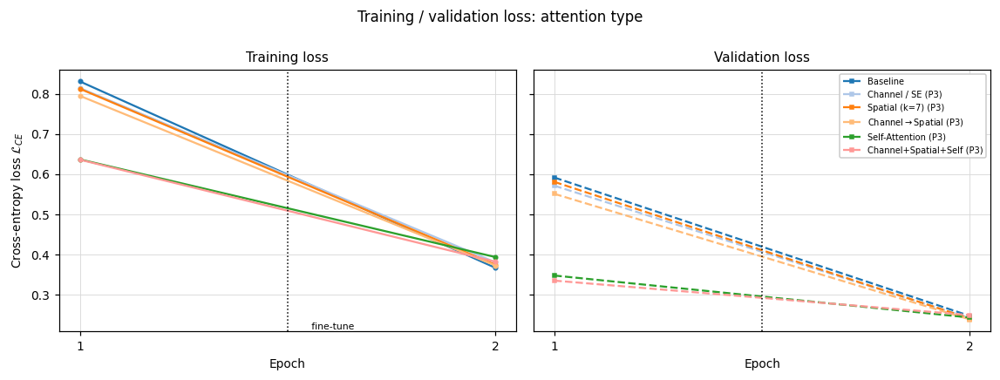

  saved -> lab8_outputs\figures\F03_loss_curves_attention_type.eps


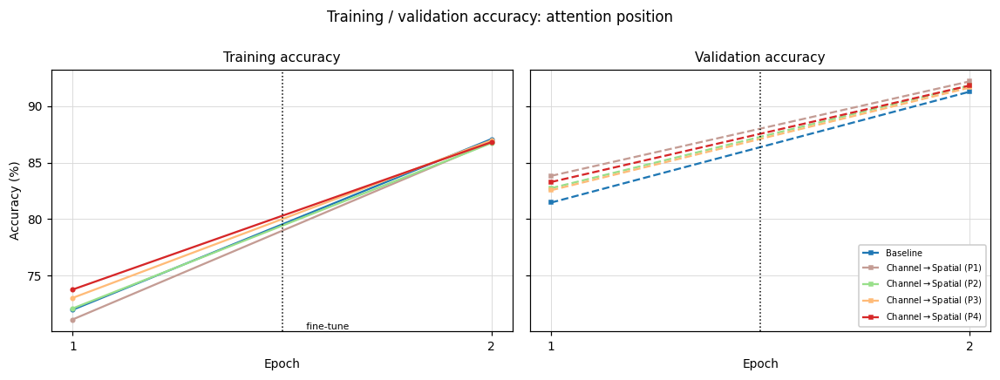

  saved -> lab8_outputs\figures\F02_accuracy_curves_attention_position.eps


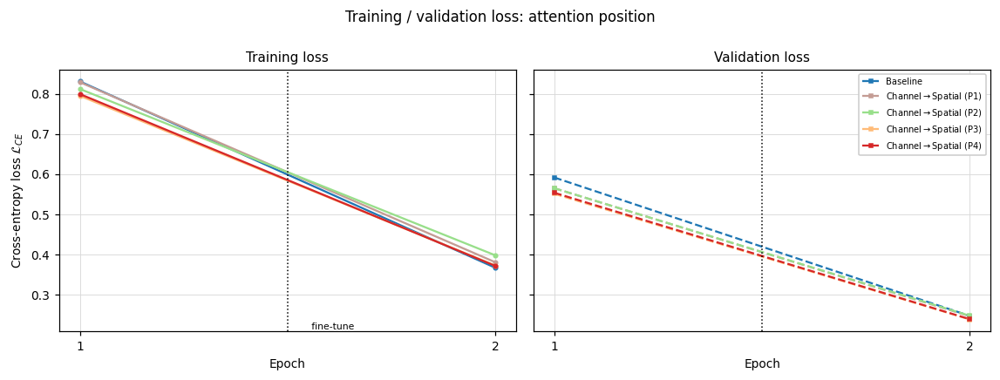

  saved -> lab8_outputs\figures\F03_loss_curves_attention_position.eps


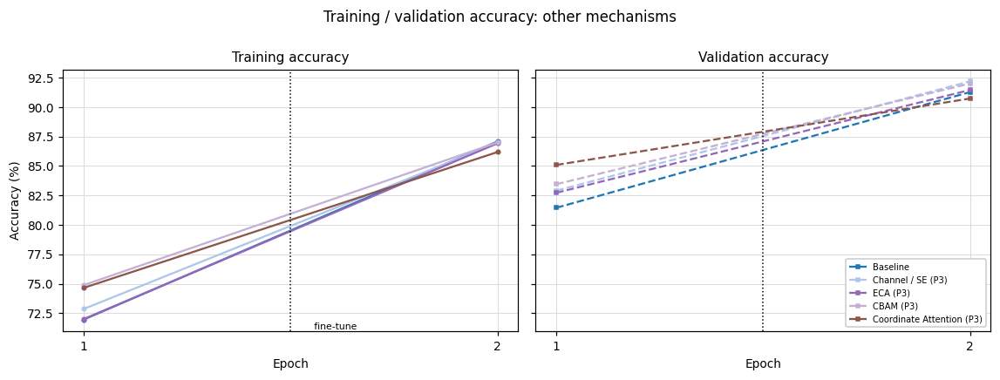

  saved -> lab8_outputs\figures\F02_accuracy_curves_other_mechanisms.eps


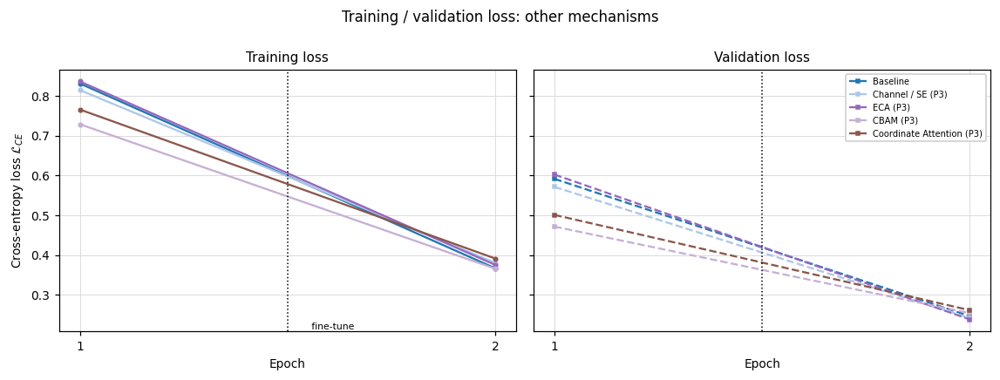

  saved -> lab8_outputs\figures\F03_loss_curves_other_mechanisms.eps


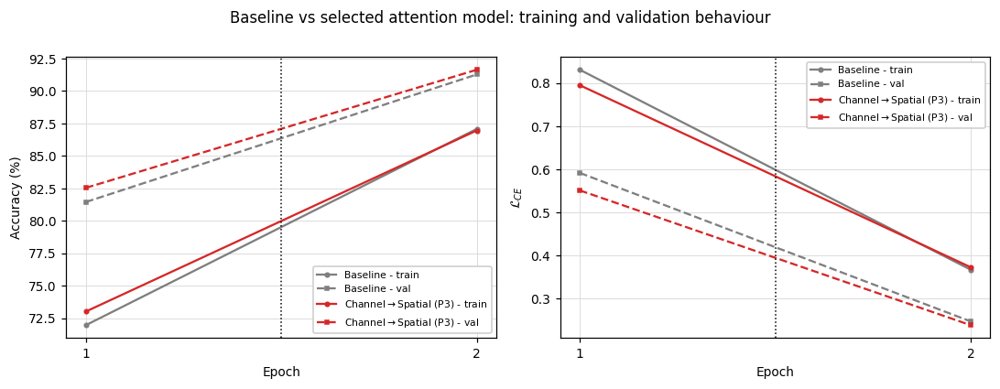

  saved -> lab8_outputs\figures\F04_baseline_vs_selected_curves.eps


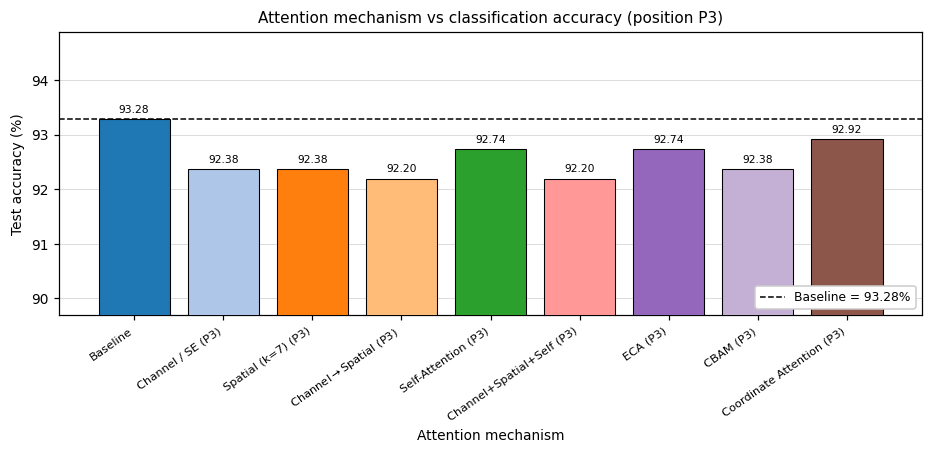

  saved -> lab8_outputs\figures\F05_bar_mechanism_vs_accuracy.eps


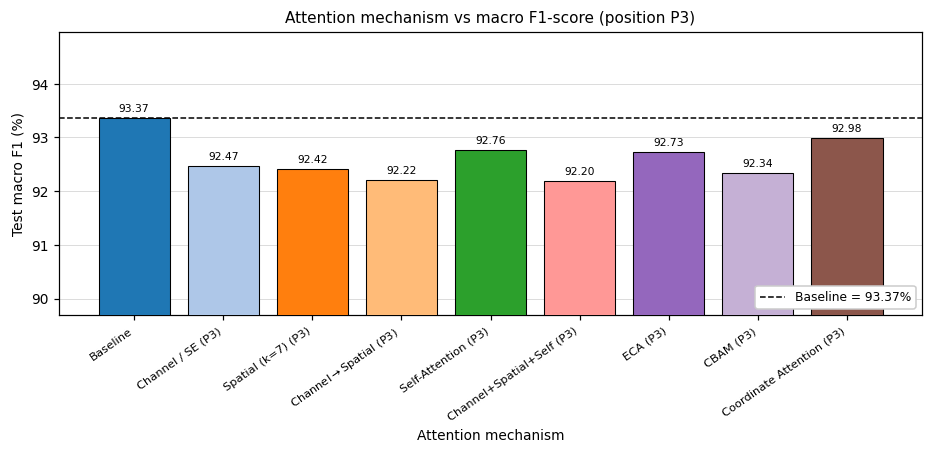

  saved -> lab8_outputs\figures\F06_bar_mechanism_vs_macroF1.eps


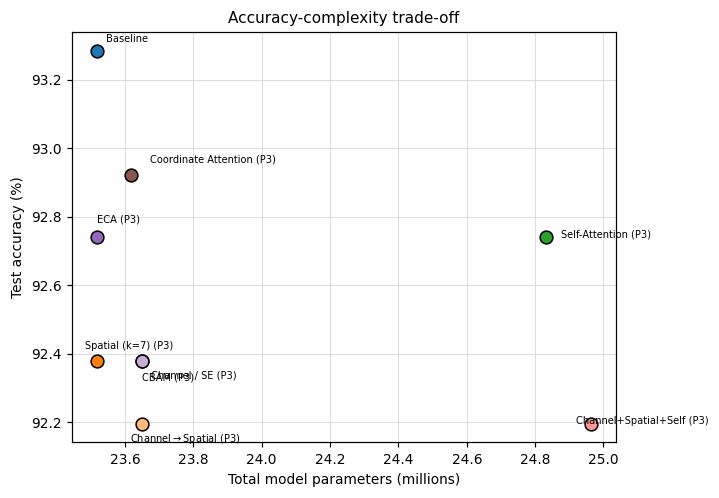

  saved -> lab8_outputs\figures\F07_scatter_accuracy_vs_parameters.eps


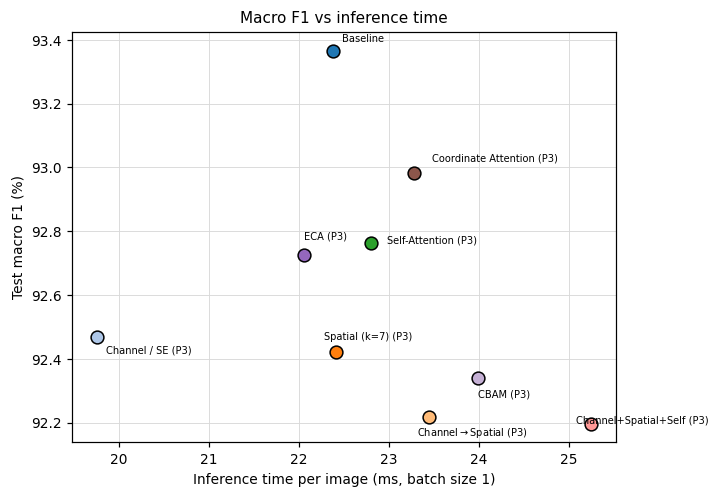

  saved -> lab8_outputs\figures\F08_scatter_macroF1_vs_inference_time.eps


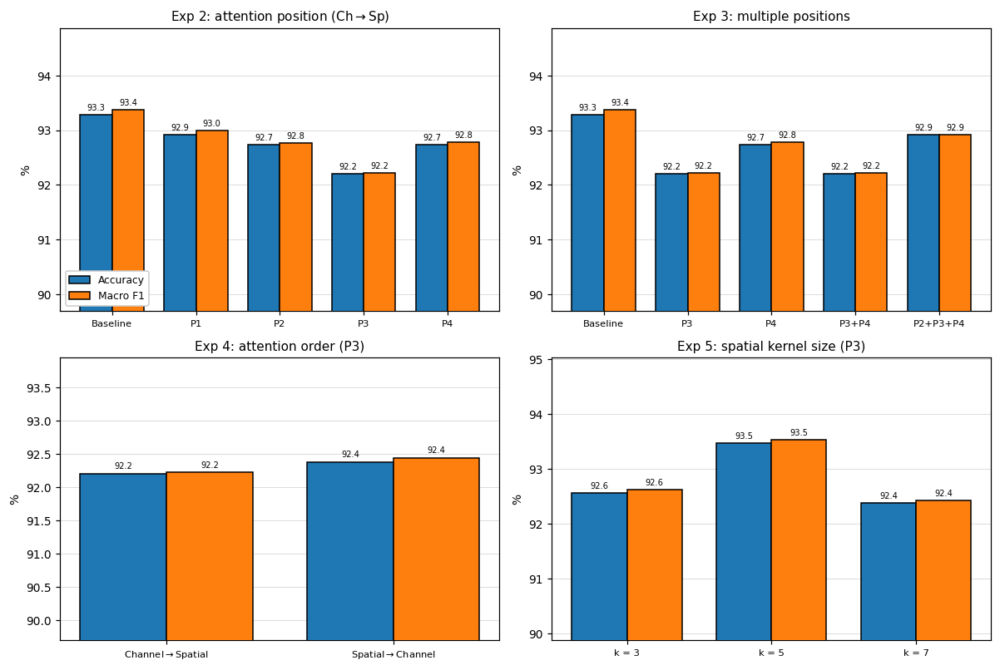

  saved -> lab8_outputs\figures\F09_ablation_summary.eps


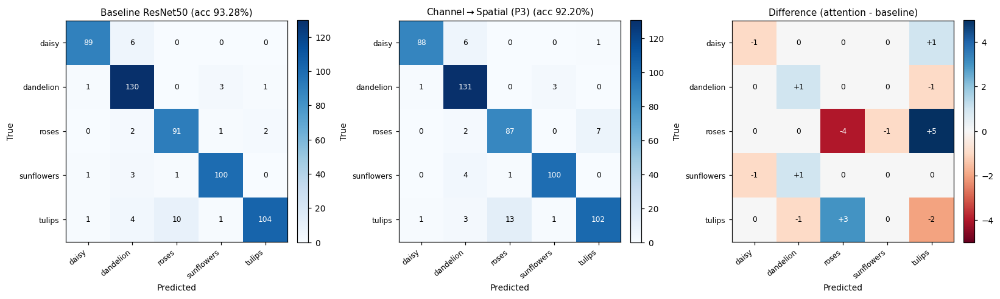

  saved -> lab8_outputs\figures\F10_confusion_matrices.eps


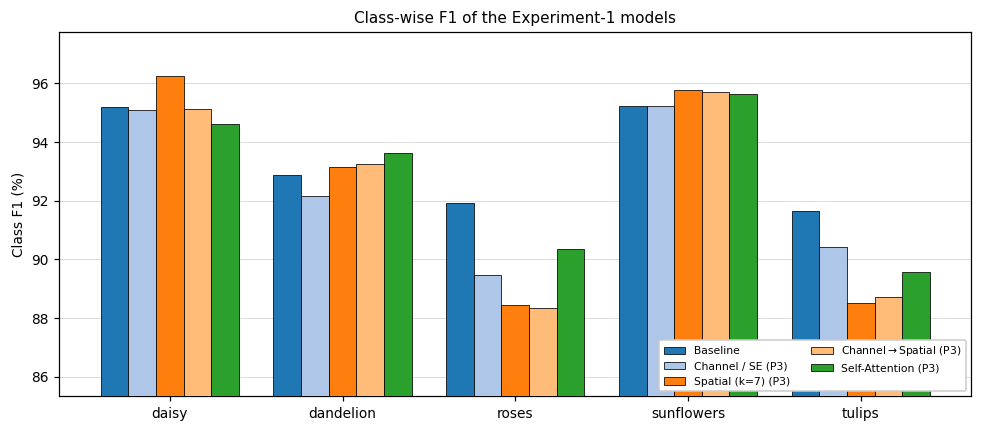

  saved -> lab8_outputs\figures\F11_classwise_F1.eps


In [12]:
# ===================== QUANTITATIVE FIGURES (all EPS, 600 dpi) =====================
ORDER = list(EXPERIMENTS.keys())
MODEL_COLOR = {n: plt.cm.tab20.colors[i % 20] for i, n in enumerate(ORDER)}
ATT_SET = ['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3', 'A5_Combined_P3',
           'X1_ECA_P3', 'X2_CBAM_P3', 'X3_CoordAtt_P3']
GROUPS = {'attention_type':     ['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3', 'A5_Combined_P3'],
          'attention_position': ['A0_Baseline', 'B1_ChSp_P1', 'B2_ChSp_P2', 'A3_ChSp_P3', 'B4_ChSp_P4'],
          'other_mechanisms':   ['A0_Baseline', 'A1_Channel_P3', 'X1_ECA_P3', 'X2_CBAM_P3', 'X3_CoordAtt_P3']}

def lab(n, nl=False):
    r = R[n]; s = f"{r['label']} ({r['pos']})" if r['pos'] != '--' else 'Baseline'
    return s.replace('->', '$\\rightarrow$')

def plot_curves(names, metric, fname, title):
    ktr, kva = ('train_acc', 'val_acc') if metric == 'acc' else ('train_loss', 'val_loss')
    sc = 100 if metric == 'acc' else 1
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
    for n in names:
        h = R[n]['hist']; ep = np.arange(1, len(h[ktr]) + 1)
        axes[0].plot(ep, np.array(h[ktr]) * sc, '-o', ms=3, lw=1.5, color=MODEL_COLOR[n], label=lab(n))
        axes[1].plot(ep, np.array(h[kva]) * sc, '--s', ms=3, lw=1.5, color=MODEL_COLOR[n], label=lab(n))
    for ax, t in zip(axes, ('Training', 'Validation')):
        ax.axvline(EH + 0.5, ls=':', color='k', lw=1)
        ax.set_xlabel('Epoch'); ax.set_title(f'{t} {"accuracy" if metric == "acc" else "loss"}')
        ax.set_xticks(range(1, EH + EF + 1)); ax.grid(True, color='0.85', lw=0.6)
    axes[0].set_ylabel('Accuracy (%)' if metric == 'acc' else r'Cross-entropy loss $\mathcal{L}_{CE}$')
    axes[0].text(EH + 0.55, axes[0].get_ylim()[0], ' fine-tune', fontsize=7, va='bottom')
    axes[1].legend(loc='lower right' if metric == 'acc' else 'upper right', fontsize=6.5)
    fig.suptitle(title, y=1.0); plt.tight_layout(); save_fig(fig, fname)

for g, names in GROUPS.items():
    plot_curves(names, 'acc',  f'F02_accuracy_curves_{g}', f'Training / validation accuracy: {g.replace("_", " ")}')
    plot_curves(names, 'loss', f'F03_loss_curves_{g}',     f'Training / validation loss: {g.replace("_", " ")}')

# --- baseline vs one selected attention model, train + val on the same axes (Sec. 24.1 / 24.2) ---
SELECTED = 'A3_ChSp_P3'
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for n, c in (('A0_Baseline', 'tab:gray'), (SELECTED, 'tab:red')):
    h = R[n]['hist']; ep = np.arange(1, len(h['train_acc']) + 1)
    axes[0].plot(ep, 100 * np.array(h['train_acc']), '-o', color=c, ms=3, label=f'{lab(n)} - train')
    axes[0].plot(ep, 100 * np.array(h['val_acc']), '--s', color=c, ms=3, label=f'{lab(n)} - val')
    axes[1].plot(ep, h['train_loss'], '-o', color=c, ms=3, label=f'{lab(n)} - train')
    axes[1].plot(ep, h['val_loss'], '--s', color=c, ms=3, label=f'{lab(n)} - val')
axes[0].set_ylabel('Accuracy (%)'); axes[1].set_ylabel(r'$\mathcal{L}_{CE}$')
for ax in axes:
    ax.axvline(EH + 0.5, ls=':', color='k', lw=1); ax.set_xlabel('Epoch'); ax.grid(True, color='0.85', lw=0.6)
    ax.set_xticks(range(1, EH + EF + 1))
axes[0].legend(fontsize=7, loc='lower right'); axes[1].legend(fontsize=7, loc='upper right')
fig.suptitle('Baseline vs selected attention model: training and validation behaviour', y=1.0)
plt.tight_layout(); save_fig(fig, 'F04_baseline_vs_selected_curves')

# --- bar charts: mechanism vs accuracy / macro F1 (Sec. 24.3, 24.4) ---
def bar_chart(names, key, ylabel, fname, title):
    vals = [100 * R[n]['test'][key] for n in names]
    fig, ax = plt.subplots(figsize=(max(6.5, 0.95 * len(names)), 4.2))
    bars = ax.bar(range(len(names)), vals, color=[MODEL_COLOR[n] for n in names], edgecolor='k', lw=0.7, zorder=3)
    base = 100 * R['A0_Baseline']['test'][key]
    ax.axhline(base, ls='--', color='k', lw=1, label=f'Baseline = {base:.2f}%', zorder=4)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.08, f'{v:.2f}', ha='center', va='bottom', fontsize=7)
    ax.set_ylim(max(0, min(vals) - 2.5), min(100.8, max(vals) + 1.6))
    ax.set_xticks(range(len(names))); ax.set_xticklabels([lab(n) for n in names], rotation=35, ha='right', fontsize=7.5)
    ax.set_ylabel(ylabel); ax.set_xlabel('Attention mechanism'); ax.set_title(title)
    ax.grid(True, axis='y', color='0.85', lw=0.6, zorder=0); ax.legend(loc='lower right')
    plt.tight_layout(); save_fig(fig, fname)

bar_chart(ATT_SET, 'acc', 'Test accuracy (%)', 'F05_bar_mechanism_vs_accuracy', 'Attention mechanism vs classification accuracy (position P3)')
bar_chart(ATT_SET, 'f1',  'Test macro F1 (%)', 'F06_bar_mechanism_vs_macroF1',  'Attention mechanism vs macro F1-score (position P3)')

# --- scatter plots (Sec. 24.5, 24.6) ---
OFFS = [(6, 6), (6, -11), (-8, 8), (-8, -12), (10, 0), (-10, 0), (0, 10), (0, -12), (12, 8)]
def scatter_plot(xf, yk, xlabel, ylabel, fname, title):
    fig, ax = plt.subplots(figsize=(6.6, 4.6))
    for i, n in enumerate(ATT_SET):
        x, y = xf(R[n]), 100 * R[n]['test'][yk]
        ax.scatter(x, y, s=70, color=MODEL_COLOR[n], edgecolor='k', zorder=3)
        ax.annotate(lab(n), (x, y), xytext=OFFS[i % len(OFFS)], textcoords='offset points', fontsize=6.5)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(True, color='0.85', lw=0.6)
    ax.ticklabel_format(useOffset=False, axis='x'); plt.tight_layout(); save_fig(fig, fname)

scatter_plot(lambda r: r['params_total'] / 1e6, 'acc', 'Total model parameters (millions)', 'Test accuracy (%)',
             'F07_scatter_accuracy_vs_parameters', 'Accuracy-complexity trade-off')
scatter_plot(lambda r: r['inf_ms_bs1'], 'f1', 'Inference time per image (ms, batch size 1)', 'Test macro F1 (%)',
             'F08_scatter_macroF1_vs_inference_time', 'Macro F1 vs inference time')

# --- summary of the four ablations (position / multi-position / order / kernel) ---
def grouped(ax, names, labels, title):
    x, w = np.arange(len(names)), 0.38
    acc = [100 * R[n]['test']['acc'] for n in names]; f1 = [100 * R[n]['test']['f1'] for n in names]
    b1 = ax.bar(x - w / 2, acc, w, color='tab:blue', edgecolor='k', label='Accuracy', zorder=3)
    b2 = ax.bar(x + w / 2, f1, w, color='tab:orange', edgecolor='k', label='Macro F1', zorder=3)
    for bb, vv in list(zip(b1, acc)) + list(zip(b2, f1)):
        ax.text(bb.get_x() + bb.get_width() / 2, vv + 0.05, f'{vv:.1f}', ha='center', va='bottom', fontsize=6.5)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7.5)
    ax.set_ylim(max(0, min(acc + f1) - 2.5), min(100.8, max(acc + f1) + 1.5)); ax.set_title(title)
    ax.grid(True, axis='y', color='0.85', lw=0.6, zorder=0); ax.set_ylabel('%')
fig, axes = plt.subplots(2, 2, figsize=(11, 7.4))
grouped(axes[0, 0], ['A0_Baseline', 'B1_ChSp_P1', 'B2_ChSp_P2', 'A3_ChSp_P3', 'B4_ChSp_P4'],
        ['Baseline', 'P1', 'P2', 'P3', 'P4'], 'Exp 2: attention position (Ch$\\rightarrow$Sp)')
grouped(axes[0, 1], ['A0_Baseline', 'A3_ChSp_P3', 'B4_ChSp_P4', 'M1_ChSp_P3P4', 'M2_ChSp_P2P3P4'],
        ['Baseline', 'P3', 'P4', 'P3+P4', 'P2+P3+P4'], 'Exp 3: multiple positions')
grouped(axes[1, 0], ['A3_ChSp_P3', 'O1_SpCh_P3'], ['Channel$\\rightarrow$Spatial', 'Spatial$\\rightarrow$Channel'], 'Exp 4: attention order (P3)')
grouped(axes[1, 1], ['K3_Spatial_P3', 'K5_Spatial_P3', 'A2_Spatial_P3'], ['k = 3', 'k = 5', 'k = 7'], 'Exp 5: spatial kernel size (P3)')
axes[0, 0].legend(loc='lower left'); plt.tight_layout(); save_fig(fig, 'F09_ablation_summary')

# --- confusion matrices: baseline, selected model and their difference (Sec. 25) ---
def draw_cm(ax, cm, title, cmap, vmin=None, vmax=None, signed=False):
    im = ax.imshow(cm, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=40, ha='right', fontsize=8); ax.set_yticklabels(CLASSES, fontsize=8)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
    top = (vmax if vmax is not None else cm.max())
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            v = cm[i, j]; dark = abs(v) > 0.55 * top
            ax.text(j, i, f'{v:+d}' if signed and v != 0 else f'{v:d}', ha='center', va='center',
                    color='white' if dark else 'black', fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cmb, cms = np.array(R['A0_Baseline']['test']['cm']), np.array(R[SELECTED]['test']['cm'])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
draw_cm(axes[0], cmb, f'Baseline ResNet50 (acc {100 * R["A0_Baseline"]["test"]["acc"]:.2f}%)', 'Blues')
draw_cm(axes[1], cms, f'{lab(SELECTED)} (acc {100 * R[SELECTED]["test"]["acc"]:.2f}%)', 'Blues')
d = cms - cmb; lim = max(1, int(np.abs(d).max()))
draw_cm(axes[2], d, 'Difference (attention - baseline)', 'RdBu', -lim, lim, signed=True)
plt.tight_layout(); save_fig(fig, 'F10_confusion_matrices')

# --- class-wise F1 for the Exp-1 models: which class benefits from attention? ---
fig, ax = plt.subplots(figsize=(9, 4))
nm = ['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3']; w = 0.16
for i, n in enumerate(nm):
    f1c = 100 * np.array(R[n]['test']['per_class']['f1'])
    ax.bar(np.arange(N_CLASSES) + (i - 2) * w, f1c, w, color=MODEL_COLOR[n], edgecolor='k', lw=0.5, label=lab(n), zorder=3)
ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(CLASSES); ax.set_ylabel('Class F1 (%)')
allf = np.concatenate([100 * np.array(R[n]['test']['per_class']['f1']) for n in nm])
ax.set_ylim(max(0, allf.min() - 3), min(100.5, allf.max() + 1.5)); ax.legend(ncol=2, fontsize=7, loc='lower right')
ax.grid(True, axis='y', color='0.85', lw=0.6, zorder=0); ax.set_title('Class-wise F1 of the Experiment-1 models')
plt.tight_layout(); save_fig(fig, 'F11_classwise_F1')

In [13]:
# ============ QUALITATIVE ANALYSIS: helpers (models, Grad-CAM, internal attention) ============
MODEL_CACHE = {}
def get_model(name):
    if name not in MODEL_CACHE:
        seed_everything(SEED)                       # same init as in training (matters only if PRETRAINED=False)
        m = AttnResNet50(EXPERIMENTS[name]['attn'], N_CLASSES, PRETRAINED, DROPOUT)
        missing_k, unexpected = m.load_state_dict(torch.load(CKPT_DIR / f'{name}.pt', map_location='cpu'), strict=False)
        assert not unexpected, unexpected
        MODEL_CACHE[name] = m.to(DEVICE).eval()
    return MODEL_CACHE[name]

def prep(idx):                                      # idx -> normalised tensor of TEST images
    return normalize(Xte[list(idx)].float().div(255.0).to(DEVICE))
def img_hwc(i): return Xte[i].permute(1, 2, 0).numpy()
def norm01(a):                                      # per-sample min-max, a: (B,H,W) torch
    mn, mx = a.amin((1, 2), keepdim=True), a.amax((1, 2), keepdim=True)
    return (a - mn) / (mx - mn + 1e-8)
def up(m):                                          # (B,h,w) -> (B,IMG,IMG)
    return F.interpolate(m[:, None].float(), size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)[:, 0]
def overlay(img, m01, alpha=0.5):                   # opaque blend (EPS has no transparency)
    heat = plt.cm.jet(m01)[..., :3]
    return np.clip((1 - alpha) * img / 255.0 + alpha * heat, 0, 1)

@torch.no_grad()
def forward_store(model, x):
    mods = [m for m in model.modules() if hasattr(m, 'store')]
    for m in mods: m.store = True
    model.record, model.cache = True, {}
    out = model(x)
    for m in mods: m.store = False
    model.record = False
    return out

def gradcam(model, x):
    """Grad-CAM on the final feature map (the tensor fed to global-average-pooling), predicted class."""
    model.eval(); x = x.clone().requires_grad_(True)
    with torch.enable_grad():
        feats = model.forward_features(x); feats.retain_grad()
        logits = model.head(feats)
        pred = logits.argmax(1)
        model.zero_grad(set_to_none=True)
        logits.gather(1, pred[:, None]).sum().backward()
    w = feats.grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * feats.detach()).sum(1, keepdim=True))
    cam = norm01(up(cam[:, 0].cpu()))
    return cam.numpy(), pred.cpu().numpy(), logits.softmax(1).max(1).values.detach().cpu().numpy()

def gradcam_many(name, idx, bs=16):
    model, cams, preds, confs = get_model(name), [], [], []
    for i in range(0, len(idx), bs):
        c, p, q = gradcam(model, prep(idx[i:i + bs])); cams.append(c); preds.append(p); confs.append(q)
    return np.concatenate(cams), np.concatenate(preds), np.concatenate(confs)

def spatial_maps(name, idx, pos):
    """internal spatial-attention map M_s (raw sigmoid values) at position `pos`."""
    model = get_model(name); forward_store(model, prep(idx))
    return find_modules(model.attn[pos], SpatialAttention)[0].last[:, 0]        # (B,h,w)

def show(ax, img, title=None, ylabel=None, cmap=None, fs=7):
    if torch.is_tensor(img): img = img.numpy()
    ax.imshow(img, cmap=cmap); ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=fs)
    if ylabel: ax.set_ylabel(ylabel, fontsize=fs)

# ------------- choose representative test images: 3 correct + 2 incorrect -------------
rng = np.random.RandomState(SEED)
P = {n: np.array(R[n]['preds']) for n in EXPERIMENTS}
CONF = {n: np.array(R[n]['conf']) for n in EXPERIMENTS}
QUAL_MODELS = ['A0_Baseline', 'A1_Channel_P3', 'A2_Spatial_P3', 'A3_ChSp_P3', 'A4_Self_P3']
ok_all = np.all([P[n] == y_te_np for n in QUAL_MODELS], axis=0)

correct = []
for c in rng.permutation(N_CLASSES):
    cand = np.where(ok_all & (y_te_np == c))[0]
    if len(cand): correct.append(int(rng.choice(cand)))
    if len(correct) == 3: break
while len(correct) < 3:                                    # fallback (tiny quick-test sets)
    c = int(rng.randint(len(y_te_np)))
    if c not in correct: correct.append(c)

wrong_pool = np.where((P['A0_Baseline'] != y_te_np) | (P[SELECTED] != y_te_np))[0]
wrong, seen = [], set()
for i in rng.permutation(wrong_pool):
    if y_te_np[i] not in seen: wrong.append(int(i)); seen.add(y_te_np[i])
    if len(wrong) == 2: break
for i in rng.permutation(len(y_te_np)):                    # fallback if fewer than 2 errors
    if len(wrong) >= 2: break
    if int(i) not in wrong and int(i) not in correct: wrong.append(int(i))
SEL_IDX = correct + wrong
print('Correct test images :', correct, [CLASSES[y_te_np[i]] for i in correct])
print('Incorrect test images:', wrong, [(CLASSES[y_te_np[i]], '->', CLASSES[P['A0_Baseline'][i]], CLASSES[P[SELECTED][i]]) for i in wrong],
      '(true, baseline pred, selected pred)')

Correct test images : [303, 366, 123] ['dandelion', 'tulips', 'roses']
Incorrect test images: [270, 157] [('tulips', '->', 'dandelion', 'dandelion'), ('daisy', '->', 'dandelion', 'dandelion')] (true, baseline pred, selected pred)


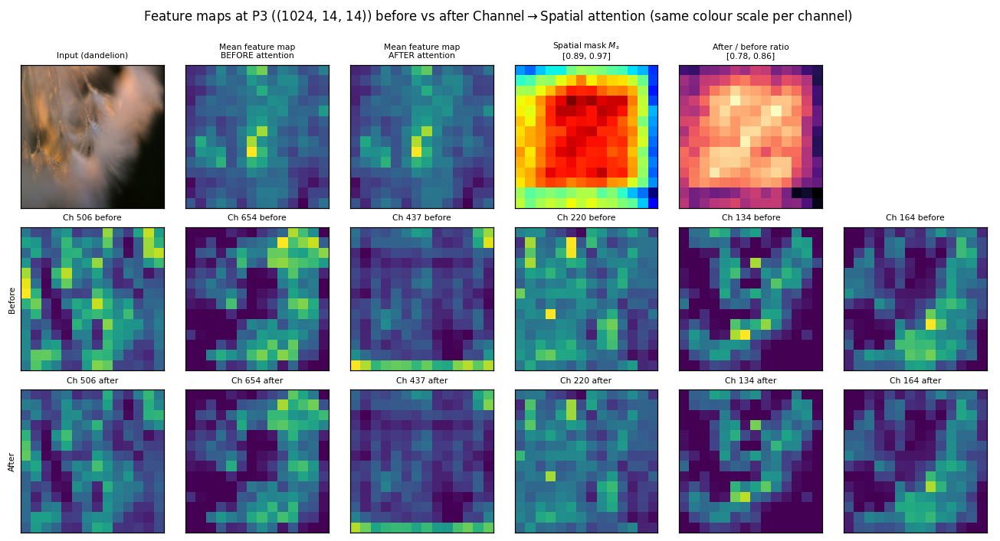

  saved -> lab8_outputs\figures\F12_feature_maps_before_after_attention_img1.eps


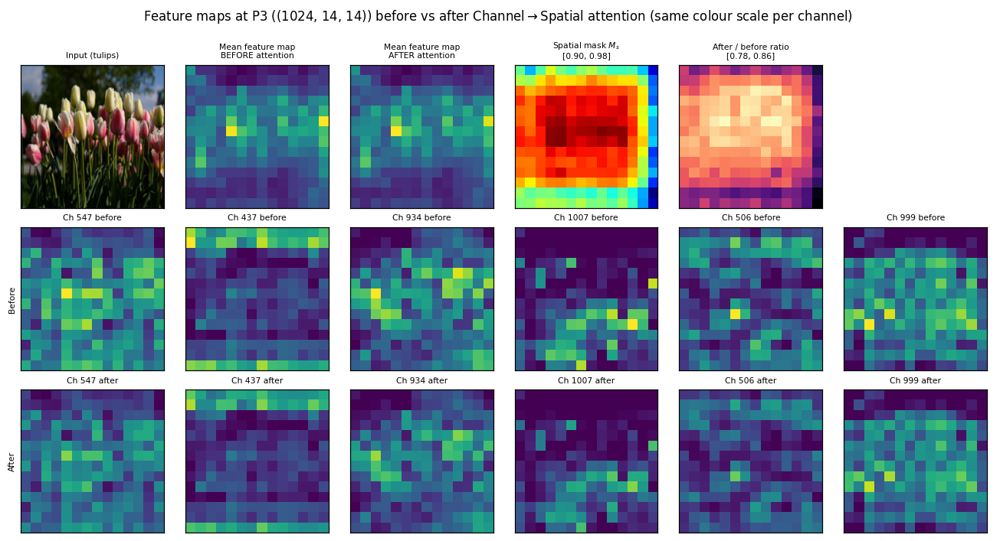

  saved -> lab8_outputs\figures\F12_feature_maps_before_after_attention_img2.eps


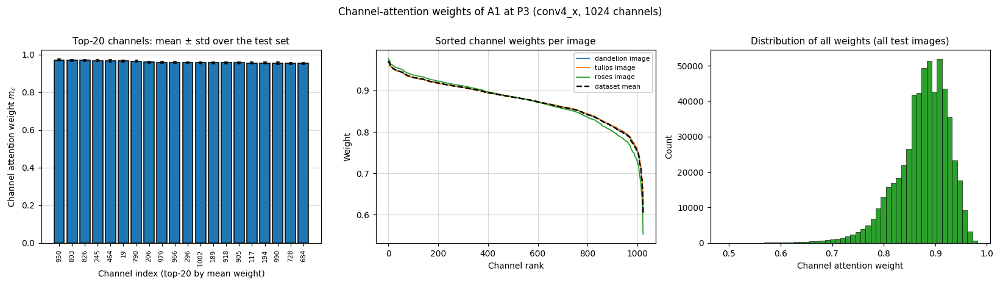

  saved -> lab8_outputs\figures\F13_channel_attention_weights.eps

### Channel-attention weight statistics (A1, P3, test set)   [T14_channel_attention_statistics.csv / T14_channel_attention_statistics.tex]


Statistic,Value
Mean weight,0.8751
Std of weights (across channels),0.0511
Fraction of channels with mean weight > 0.5,1.000
Mean per-channel std across images,0.0046
Mean coefficient of variation across images,0.0055
Mean weight of top-20 channels,0.9598
Mean weight of all channels,0.8751
Min / Max weight,0.488 / 0.982


In [14]:
# ===== Feature maps before / after attention (selected model) + channel-attention weights =====
model = get_model(SELECTED)
for k, i0 in enumerate(correct[:2]):
    x = prep([i0]); forward_store(model, x)
    before, after = model.cache['P3_before'][0], model.cache['P3_after'][0]          # (C,H,W)
    sa = find_modules(model.attn['P3'], SpatialAttention)[0].last[0, 0]
    top = torch.argsort(before.mean((1, 2)), descending=True)[:6]                  # 6 most active channels
    fig, axes = plt.subplots(3, 6, figsize=(12, 6.4))
    show(axes[0, 0], img_hwc(i0), f'Input ({CLASSES[y_te_np[i0]]})')
    show(axes[0, 1], before.mean(0), 'Mean feature map\nBEFORE attention', cmap='viridis')
    show(axes[0, 2], after.mean(0), 'Mean feature map\nAFTER attention', cmap='viridis')
    show(axes[0, 3], sa, f'Spatial mask $M_s$\n[{sa.min():.2f}, {sa.max():.2f}]', cmap='jet')
    ratio = (after.mean(0) / (before.mean(0) + 1e-6))
    show(axes[0, 4], ratio, f'After / before ratio\n[{ratio.min():.2f}, {ratio.max():.2f}]', cmap='magma')
    axes[0, 5].axis('off')
    for j, ch in enumerate(top.tolist()):
        vmax = float(before[ch].max())
        show(axes[1, j], before[ch], f'Ch {ch} before', cmap='viridis', ylabel='Before' if j == 0 else None)
        axes[1, j].images[0].set_clim(0, vmax)
        show(axes[2, j], after[ch], f'Ch {ch} after', cmap='viridis', ylabel='After' if j == 0 else None)
        axes[2, j].images[0].set_clim(0, vmax)
    fig.suptitle(f'Feature maps at P3 ({tuple(before.shape)}) before vs after Channel$\\rightarrow$Spatial attention '
                 f'(same colour scale per channel)', y=0.995)
    plt.tight_layout(); save_fig(fig, f'F12_feature_maps_before_after_attention_img{k + 1}')

# ---------------- channel-attention weights (Channel model A1 at P3) ----------------
mA1 = get_model('A1_Channel_P3'); Wt = []
for i in range(0, len(Xte), 32):
    forward_store(mA1, prep(range(i, min(i + 32, len(Xte)))))
    Wt.append(find_modules(mA1.attn['P3'], ChannelAttention)[0].last)
Wt = torch.cat(Wt).numpy()                                      # (N_test, 1024)
Wm, Ws = Wt.mean(0), Wt.std(0); K = 20; topk = np.argsort(-Wm)[:K]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].bar(range(K), Wm[topk], yerr=Ws[topk], color='tab:blue', edgecolor='k', capsize=2, zorder=3)
axes[0].set_xticks(range(K)); axes[0].set_xticklabels(topk, rotation=90, fontsize=7)
axes[0].set_xlabel('Channel index (top-20 by mean weight)'); axes[0].set_ylabel('Channel attention weight $m_c$')
axes[0].set_title('Top-20 channels: mean $\\pm$ std over the test set'); axes[0].grid(True, axis='y', color='0.85', zorder=0)
for j, i0 in enumerate(correct):
    axes[1].plot(np.sort(Wt[i0])[::-1], lw=1.2, color=plt.cm.tab10(j), label=f'{CLASSES[y_te_np[i0]]} image')
axes[1].plot(np.sort(Wm)[::-1], 'k--', lw=1.6, label='dataset mean')
axes[1].set_xlabel('Channel rank'); axes[1].set_ylabel('Weight'); axes[1].legend(fontsize=7)
axes[1].set_title('Sorted channel weights per image'); axes[1].grid(True, color='0.85')
axes[2].hist(Wt.ravel(), bins=50, color='tab:green', edgecolor='k', lw=0.4)
axes[2].set_xlabel('Channel attention weight'); axes[2].set_ylabel('Count'); axes[2].set_title('Distribution of all weights (all test images)')
fig.suptitle('Channel-attention weights of A1 at P3 (conv4_x, 1024 channels)', y=1.0)
plt.tight_layout(); save_fig(fig, 'F13_channel_attention_weights')

df_ch = pd.DataFrame({'Statistic': ['Mean weight', 'Std of weights (across channels)', 'Fraction of channels with mean weight > 0.5',
                                    'Mean per-channel std across images', 'Mean coefficient of variation across images',
                                    'Mean weight of top-20 channels', 'Mean weight of all channels', 'Min / Max weight'],
                      'Value': [f'{Wt.mean():.4f}', f'{Wm.std():.4f}', f'{(Wm > 0.5).mean():.3f}', f'{Ws.mean():.4f}',
                                f'{(Ws / (Wm + 1e-8)).mean():.4f}', f'{Wm[topk].mean():.4f}', f'{Wm.mean():.4f}',
                                f'{Wt.min():.3f} / {Wt.max():.3f}']})
save_table(df_ch, 'T14_channel_attention_statistics', 'Channel-attention weight statistics (A1, P3, test set)')

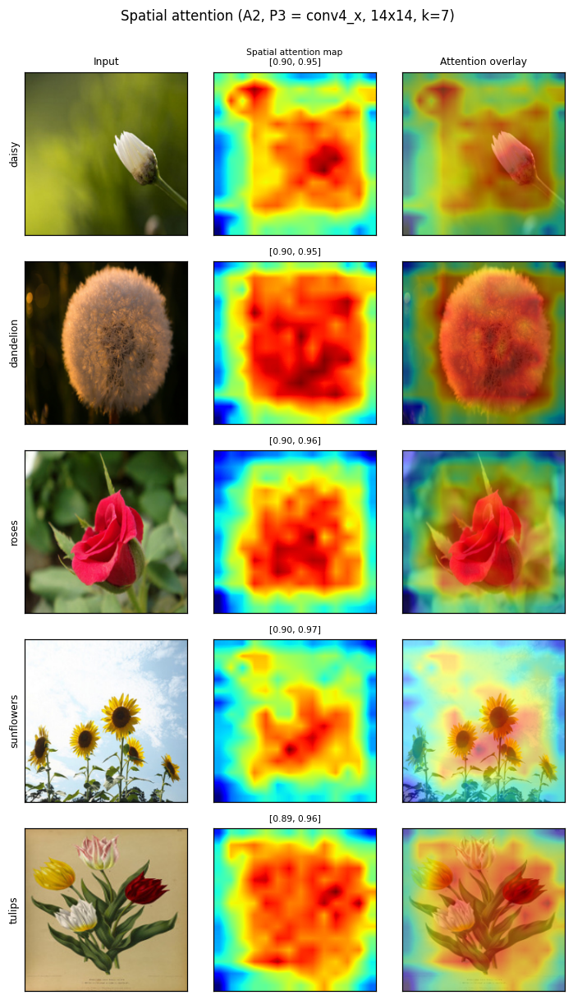

  saved -> lab8_outputs\figures\F14_spatial_attention_map_overlay.eps


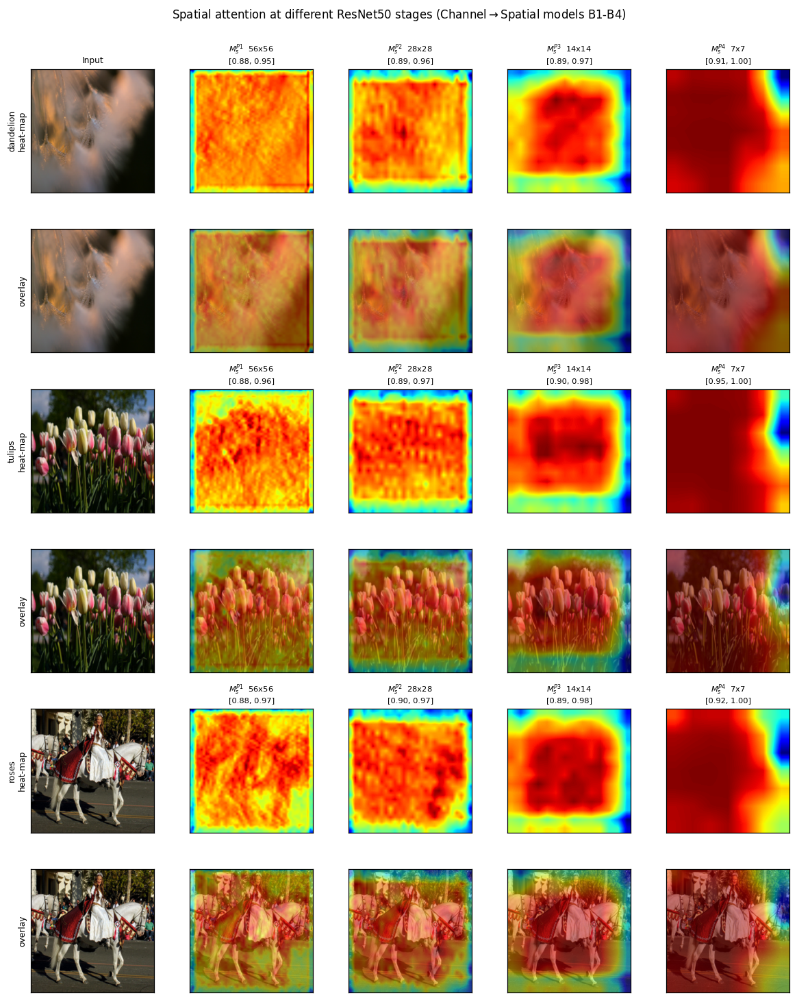

  saved -> lab8_outputs\figures\F15_spatial_attention_at_P1_P2_P3_P4.eps


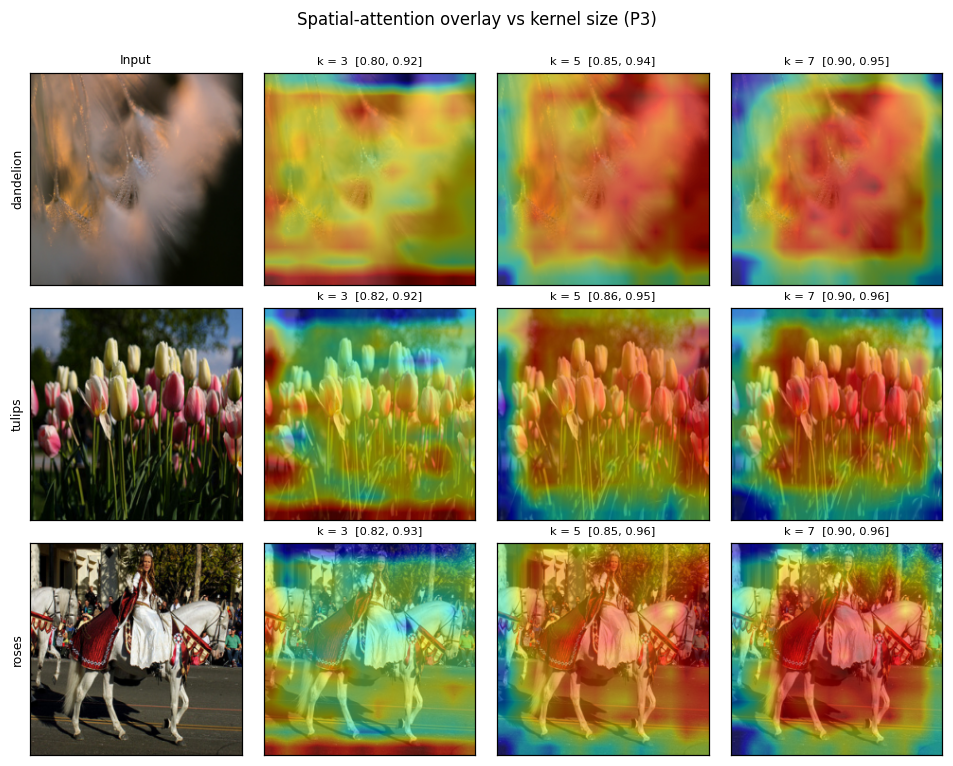

  saved -> lab8_outputs\figures\F16_spatial_attention_kernel_size.eps


In [15]:
# ===== Spatial-attention heatmap + overlay (A2), maps at P1..P4 (B1..B4), kernel sizes =====
def one_per_class():
    rr = np.random.RandomState(SEED + 1)
    return [int(rr.choice(np.where(y_te_np == c)[0])) for c in range(N_CLASSES) if (y_te_np == c).any()]
IDX5 = one_per_class()

# ---- Sec. 28.2: Input | Spatial attention map | Overlay (spatial-only model, P3) ----
sm = spatial_maps('A2_Spatial_P3', IDX5, 'P3'); smu = up(sm); sm01 = norm01(smu).numpy()
fig, axes = plt.subplots(len(IDX5), 3, figsize=(6.6, 2.2 * len(IDX5)))
for r_, i0 in enumerate(IDX5):
    rng_txt = f'[{sm[r_].min():.2f}, {sm[r_].max():.2f}]'
    show(axes[r_, 0], img_hwc(i0), 'Input' if r_ == 0 else None, ylabel=CLASSES[y_te_np[i0]], fs=8)
    show(axes[r_, 1], sm01[r_], ('Spatial attention map\n' if r_ == 0 else '') + rng_txt, cmap='jet', fs=7)
    show(axes[r_, 2], overlay(img_hwc(i0), sm01[r_]), 'Attention overlay' if r_ == 0 else None, fs=8)
fig.suptitle('Spatial attention (A2, P3 = conv4_x, 14x14, k=7)', y=1.0)
plt.tight_layout(); save_fig(fig, 'F14_spatial_attention_map_overlay')

# ---- Sec. 29: attention position visualisation  Input | M_s^P1 | M_s^P2 | M_s^P3 | M_s^P4 ----
POS_MODELS = [('B1_ChSp_P1', 'P1'), ('B2_ChSp_P2', 'P2'), ('A3_ChSp_P3', 'P3'), ('B4_ChSp_P4', 'P4')]
maps = {p: spatial_maps(n, correct, p) for n, p in POS_MODELS}
fig, axes = plt.subplots(2 * len(correct), 5, figsize=(11, 4.4 * len(correct)))
for r_, i0 in enumerate(correct):
    show(axes[2 * r_, 0], img_hwc(i0), 'Input' if r_ == 0 else None, ylabel=f'{CLASSES[y_te_np[i0]]}\nheat-map', fs=8)
    show(axes[2 * r_ + 1, 0], img_hwc(i0), None, ylabel='overlay', fs=8)
    for j, (n, p) in enumerate(POS_MODELS, start=1):
        m = maps[p][r_:r_ + 1]; m01 = norm01(up(m))[0].numpy()
        hw = tuple(m.shape[1:])
        show(axes[2 * r_, j], m01, f'$M_s^{{{p}}}$  {hw[0]}x{hw[1]}\n[{m.min():.2f}, {m.max():.2f}]', cmap='jet', fs=7.5)
        show(axes[2 * r_ + 1, j], overlay(img_hwc(i0), m01), None)
fig.suptitle('Spatial attention at different ResNet50 stages (Channel$\\rightarrow$Spatial models B1-B4)', y=1.0)
plt.tight_layout(); save_fig(fig, 'F15_spatial_attention_at_P1_P2_P3_P4')

# ---- Exp-5 visual: kernel size 3 / 5 / 7 (spatial-only attention at P3) ----
KM = [('K3_Spatial_P3', 'k = 3'), ('K5_Spatial_P3', 'k = 5'), ('A2_Spatial_P3', 'k = 7')]
kmaps = {t: spatial_maps(n, correct, 'P3') for n, t in KM}
fig, axes = plt.subplots(len(correct), 4, figsize=(8.8, 2.3 * len(correct)))
for r_, i0 in enumerate(correct):
    show(axes[r_, 0], img_hwc(i0), 'Input' if r_ == 0 else None, ylabel=CLASSES[y_te_np[i0]], fs=8)
    for j, (n, t) in enumerate(KM, start=1):
        m = kmaps[t][r_:r_ + 1]
        show(axes[r_, j], overlay(img_hwc(i0), norm01(up(m))[0].numpy()), f'{t}  [{m.min():.2f}, {m.max():.2f}]', fs=7.5)
fig.suptitle('Spatial-attention overlay vs kernel size (P3)', y=1.0)
plt.tight_layout(); save_fig(fig, 'F16_spatial_attention_kernel_size')

learned gamma = 0.0703


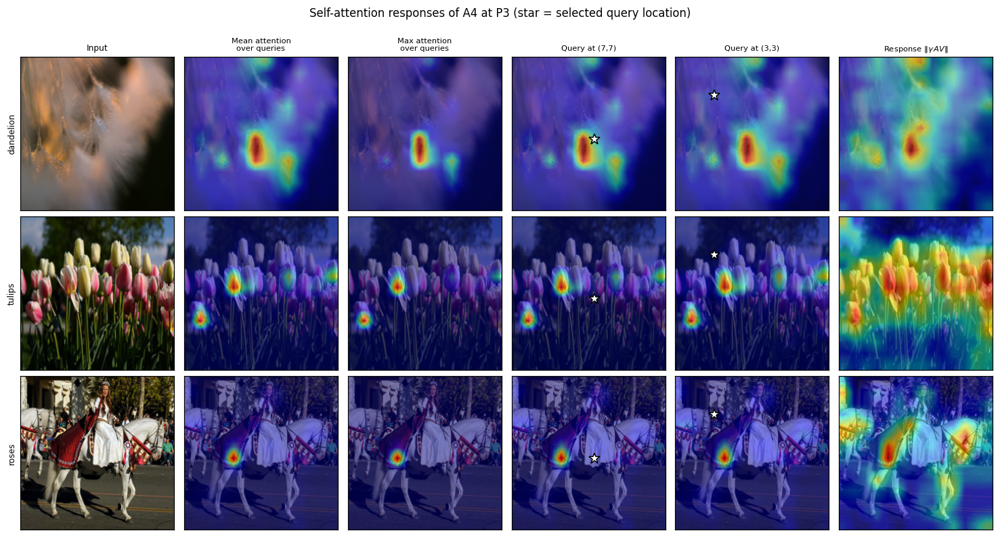

  saved -> lab8_outputs\figures\F17_self_attention_response.eps

### Size of the self-attention matrix at each position   [T15_self_attention_matrix_size.csv / T15_self_attention_matrix_size.tex]


Position,Resolution,N = HW tokens,Attention matrix entries (N^2),"Matrix size per image, fp32 (MB)"
P1,56x56,3136,9834496,39.34
P2,28x28,784,614656,2.46
P3,14x14,196,38416,0.15
P4,7x7,49,2401,0.01


In [16]:
# ===== Sec. 28.3: self-attention response (A4 at P3, 14x14 -> N = 196 tokens) =====
mSA = get_model('A4_Self_P3'); blkSA = find_modules(mSA.attn['P3'], SelfAttention2d)[0]
print(f'learned gamma = {blkSA.gamma.item():.4f}')
forward_store(mSA, prep(correct))
A, RESP = blkSA.last_attn, blkSA.last_resp                      # (B,N,N), (B,C,H,W)
Hs, Ws_ = RESP.shape[2], RESP.shape[3]
queries = [(Hs // 2, Ws_ // 2), (Hs // 4, Ws_ // 4)]
cols = ['Input', 'Mean attention\nover queries', 'Max attention\nover queries',
        f'Query at ({queries[0][0]},{queries[0][1]})', f'Query at ({queries[1][0]},{queries[1][1]})',
        r'Response $\|\gamma\,AV\|$']
fig, axes = plt.subplots(len(correct), 6, figsize=(13.5, 2.4 * len(correct)))
for r_, i0 in enumerate(correct):
    a = A[r_]
    maps_ = [a.mean(0).reshape(Hs, Ws_), a.max(0).values.reshape(Hs, Ws_),
             a[queries[0][0] * Ws_ + queries[0][1]].reshape(Hs, Ws_), a[queries[1][0] * Ws_ + queries[1][1]].reshape(Hs, Ws_),
             RESP[r_].norm(dim=0)]
    show(axes[r_, 0], img_hwc(i0), cols[0] if r_ == 0 else None, ylabel=CLASSES[y_te_np[i0]], fs=8)
    for j, m in enumerate(maps_, start=1):
        m01 = norm01(up(m[None]))[0].numpy()
        show(axes[r_, j], overlay(img_hwc(i0), m01), cols[j] if r_ == 0 else None, fs=7.5)
        if j in (3, 4):
            qi, qj = queries[j - 3]
            axes[r_, j].plot((qj + 0.5) * IMG_SIZE / Ws_, (qi + 0.5) * IMG_SIZE / Hs, '*', color='white', mec='k', ms=11)
fig.suptitle('Self-attention responses of A4 at P3 (star = selected query location)', y=1.0)
plt.tight_layout(); save_fig(fig, 'F17_self_attention_response')

# attention-matrix size grows as (HW)^2 -> why self-attention is expensive at high resolution (Q13/Q14)
df_sa = pd.DataFrame({'Position': ['P1', 'P2', 'P3', 'P4'],
                      'Resolution': [f'{IMG_SIZE // 4}x{IMG_SIZE // 4}', f'{IMG_SIZE // 8}x{IMG_SIZE // 8}',
                                     f'{IMG_SIZE // 16}x{IMG_SIZE // 16}', f'{IMG_SIZE // 32}x{IMG_SIZE // 32}']})
df_sa['N = HW tokens'] = [(IMG_SIZE // s) ** 2 for s in (4, 8, 16, 32)]
df_sa['Attention matrix entries (N^2)'] = df_sa['N = HW tokens'] ** 2
df_sa['Matrix size per image, fp32 (MB)'] = df_sa['Attention matrix entries (N^2)'] * 4 / 1e6
save_table(df_sa, 'T15_self_attention_matrix_size', 'Size of the self-attention matrix at each position')

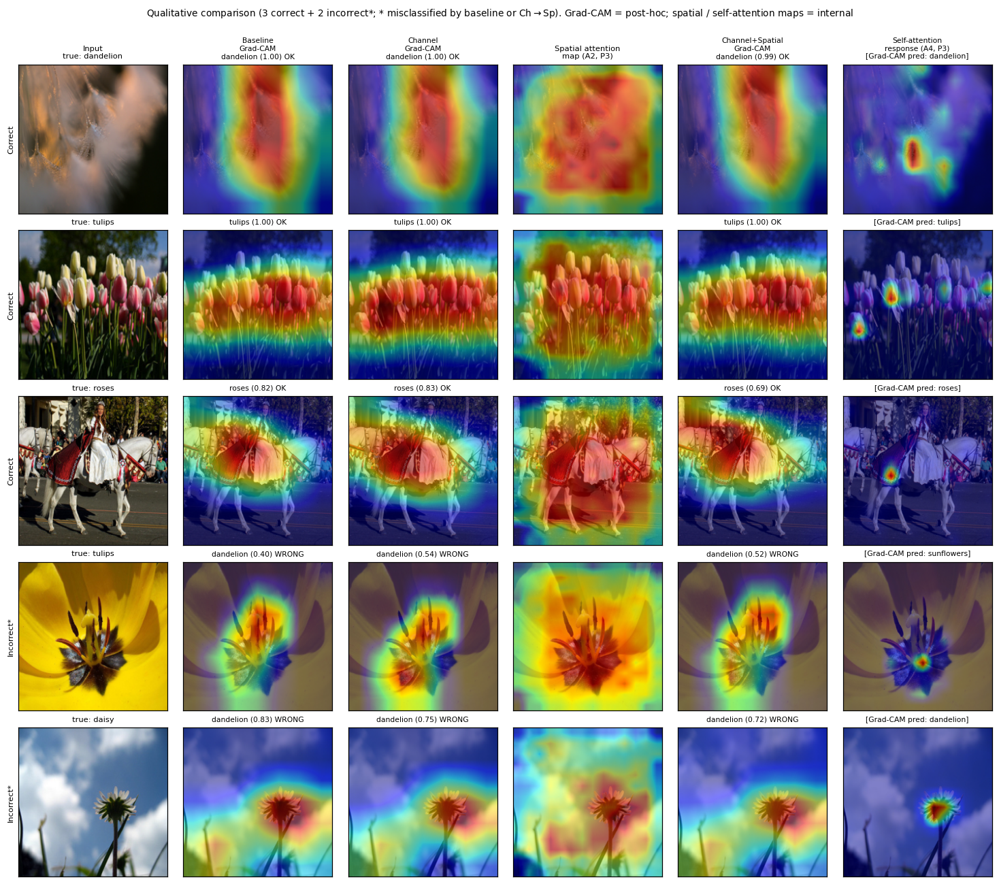

  saved -> lab8_outputs\figures\F18_qualitative_comparison_gradcam_attention.eps


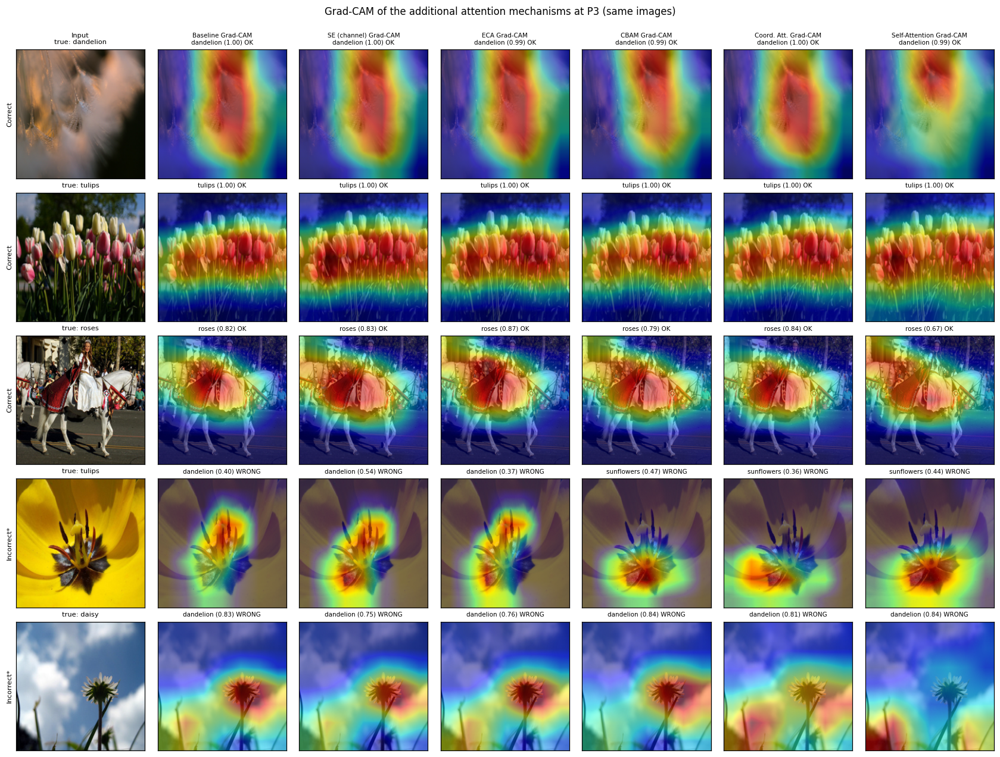

  saved -> lab8_outputs\figures\F19_gradcam_additional_mechanisms.eps


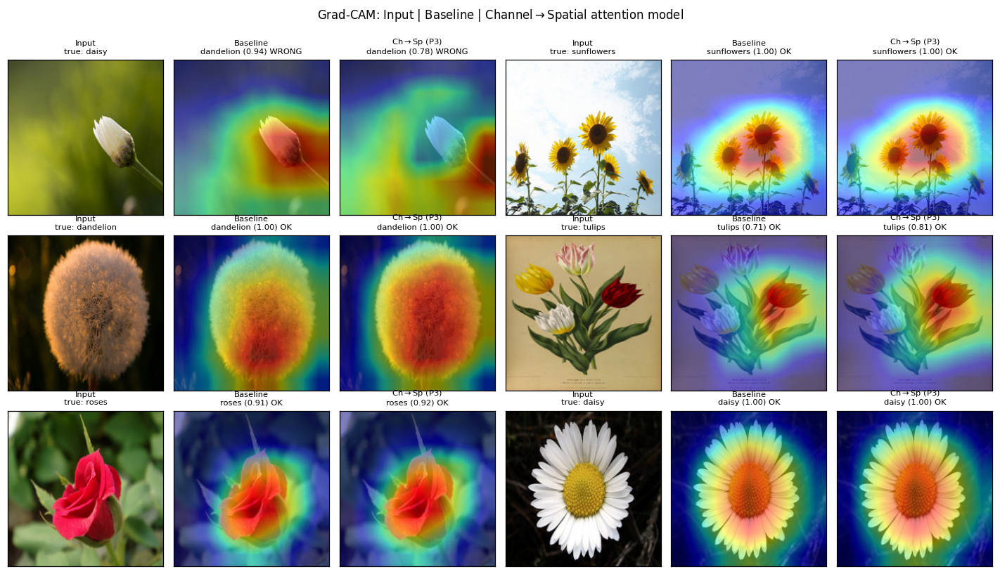

  saved -> lab8_outputs\figures\F20_gradcam_baseline_vs_selected.eps

### Grad-CAM statistics over 200 test images (lower coverage = more compact)   [T16_gradcam_statistics.csv / T16_gradcam_statistics.tex]


Model,Position,Coverage: area with CAM>=0.5 (%),Concentration: CAM mass in top-10% pixels (%),Accuracy on these images (%)
A0: Baseline ResNet50,--,34.27,25.07,95.00
A1: Channel / SE,P3,34.14,25.43,95.00
A2: Spatial (k=7),P3,34.60,24.85,95.00
A3: Channel->Spatial,P3,35.21,24.78,95.00
A4: Self-Attention,P3,37.51,23.24,94.00
A5: Channel+Spatial+Self,P3,35.61,24.13,95.00
X1: ECA,P3,35.14,24.96,94.50
X2: CBAM,P3,34.42,25.13,95.50
X3: Coordinate Attention,P3,37.19,24.26,94.00


In [17]:
# ============================ Grad-CAM comparisons ============================
def cam_cell(name, idx):
    c, p, q = gradcam_many(name, idx)
    return c, p, q

def cam_title(short, pred, conf, true):
    mark = 'OK' if pred == true else 'WRONG'
    return f'{short}\n{CLASSES[pred]} ({conf:.2f}) {mark}'

# ---------- Fig A (Sec. 30 + 32): 3 correct + 2 incorrect images, 6 columns ----------
CAM = {n: cam_cell(n, SEL_IDX) for n in ['A0_Baseline', 'A1_Channel_P3', 'A3_ChSp_P3', 'A4_Self_P3']}
sm_sel = norm01(up(spatial_maps('A2_Spatial_P3', SEL_IDX, 'P3'))).numpy()
mSA = get_model('A4_Self_P3'); forward_store(mSA, prep(SEL_IDX))
_blk = find_modules(mSA.attn['P3'], SelfAttention2d)[0]
_h = int(round(math.sqrt(_blk.last_attn.shape[1])))
sa_resp = norm01(up(_blk.last_attn.mean(1).reshape(len(SEL_IDX), _h, _h))).numpy()   # attention received per location

heads = ['Input', 'Baseline\nGrad-CAM', 'Channel\nGrad-CAM', 'Spatial attention\nmap (A2, P3)', 'Channel+Spatial\nGrad-CAM', 'Self-attention\nresponse (A4, P3)']
fig, axes = plt.subplots(len(SEL_IDX), 6, figsize=(13.5, 2.35 * len(SEL_IDX)))
for r_, i0 in enumerate(SEL_IDX):
    t = int(y_te_np[i0]); img = img_hwc(i0)
    kind = 'Correct' if r_ < 3 else 'Incorrect*'
    show(axes[r_, 0], img, f'{heads[0]}\ntrue: {CLASSES[t]}' if r_ == 0 else f'true: {CLASSES[t]}', ylabel=kind, fs=7.5)
    for j, n in zip((1, 2, 4), ('A0_Baseline', 'A1_Channel_P3', 'A3_ChSp_P3')):
        c, p, q = CAM[n]
        show(axes[r_, j], overlay(img, c[r_]), cam_title(heads[j] if r_ == 0 else '', p[r_], q[r_], t).strip('\n'), fs=7)
    show(axes[r_, 3], overlay(img, sm_sel[r_]), heads[3] if r_ == 0 else None, fs=7.5)
    c, p, q = CAM['A4_Self_P3']
    show(axes[r_, 5], overlay(img, sa_resp[r_]), (heads[5] + f'\n[Grad-CAM pred: {CLASSES[p[r_]]}]') if r_ == 0 else f'[Grad-CAM pred: {CLASSES[p[r_]]}]', fs=7)
fig.suptitle('Qualitative comparison (3 correct + 2 incorrect*; * misclassified by baseline or Ch$\\rightarrow$Sp). '
             'Grad-CAM = post-hoc; spatial / self-attention maps = internal', y=1.0, fontsize=9)
plt.tight_layout(); save_fig(fig, 'F18_qualitative_comparison_gradcam_attention')

# ---------- Fig B (Sec. 32 extended): Input | Baseline | SE | ECA | CBAM | CoordAtt | Self-Attention (Grad-CAM) ----------
EXT = [('A0_Baseline', 'Baseline'), ('A1_Channel_P3', 'SE (channel)'), ('X1_ECA_P3', 'ECA'),
       ('X2_CBAM_P3', 'CBAM'), ('X3_CoordAtt_P3', 'Coord. Att.'), ('A4_Self_P3', 'Self-Attention')]
CAMX = {n: (CAM[n] if n in CAM else cam_cell(n, SEL_IDX)) for n, _ in EXT}
fig, axes = plt.subplots(len(SEL_IDX), 1 + len(EXT), figsize=(2.2 * (1 + len(EXT)), 2.3 * len(SEL_IDX)))
for r_, i0 in enumerate(SEL_IDX):
    t = int(y_te_np[i0]); img = img_hwc(i0)
    show(axes[r_, 0], img, ('Input\n' if r_ == 0 else '') + f'true: {CLASSES[t]}', ylabel='Correct' if r_ < 3 else 'Incorrect*', fs=7.5)
    for j, (n, s) in enumerate(EXT, start=1):
        c, p, q = CAMX[n]
        show(axes[r_, j], overlay(img, c[r_]), cam_title(s + ' Grad-CAM' if r_ == 0 else '', p[r_], q[r_], t).strip('\n'), fs=6.8)
fig.suptitle('Grad-CAM of the additional attention mechanisms at P3 (same images)', y=1.0)
plt.tight_layout(); save_fig(fig, 'F19_gradcam_additional_mechanisms')

# ---------- Fig C (Sec. 27): Input | Baseline Grad-CAM | selected-model Grad-CAM on 6 more images ----------
rr = np.random.RandomState(SEED + 7)
IDX6 = IDX5 + [int(rr.randint(len(y_te_np)))]
cb, pb, qb = cam_cell('A0_Baseline', IDX6); cs_, ps_, qs_ = cam_cell(SELECTED, IDX6)
fig, axes = plt.subplots(3, 6, figsize=(13, 7.4))
for k, i0 in enumerate(IDX6):
    r_, c0 = k % 3, 3 * (k // 3); t = int(y_te_np[i0]); img = img_hwc(i0)
    show(axes[r_, c0], img, f'Input\ntrue: {CLASSES[t]}', fs=7.5)
    show(axes[r_, c0 + 1], overlay(img, cb[k]), cam_title('Baseline', pb[k], qb[k], t), fs=7.5)
    show(axes[r_, c0 + 2], overlay(img, cs_[k]), cam_title('Ch$\\rightarrow$Sp (P3)', ps_[k], qs_[k], t), fs=7.5)
fig.suptitle('Grad-CAM: Input | Baseline | Channel$\\rightarrow$Spatial attention model', y=1.0)
plt.tight_layout(); save_fig(fig, 'F20_gradcam_baseline_vs_selected')

# ---------- Grad-CAM statistics over many test images (coverage / concentration) ----------
N_CAM = min(CAM_EVAL_N, len(Xte)); idx_cam = list(range(N_CAM)); rows = []
for n in ATT_SET:
    c, p, q = cam_cell(n, idx_cam); flat = np.sort(c.reshape(N_CAM, -1), axis=1)[:, ::-1]
    top10 = flat[:, :max(1, flat.shape[1] // 10)].sum(1) / (flat.sum(1) + 1e-8)
    rows.append({'Model': f"{R[n]['id']}: {R[n]['label']}", 'Position': R[n]['pos'],
                 'Coverage: area with CAM>=0.5 (%)': 100 * (c >= 0.5).mean(),
                 'Concentration: CAM mass in top-10% pixels (%)': 100 * top10.mean(),
                 'Accuracy on these images (%)': 100 * float((p == y_te_np[:N_CAM]).mean())})
df_cam = pd.DataFrame(rows)
save_table(df_cam, 'T16_gradcam_statistics', f'Grad-CAM statistics over {N_CAM} test images (lower coverage = more compact)')

In [18]:
# ============================== FINAL SUMMARY ==============================
eps_files = sorted(FIG_DIR.glob('*.eps')); tab_files = sorted(TAB_DIR.glob('*.csv'))
print(f'{len(eps_files)} EPS figures (saved at {EPS_DPI} dpi) in  {FIG_DIR}')
print(f'{len(tab_files)} tables (CSV + LaTeX) in            {TAB_DIR}')
best = df_master.sort_values('Accuracy (%)', ascending=False).iloc[0]
print(f"\nBest test accuracy: {best['Model']} @ {best['Position']} -> {best['Accuracy (%)']:.2f}%  "
      f"(baseline {df_master.iloc[0]['Accuracy (%)']:.2f}%)")
print('\nNOTE: with only a few epochs and one seed, differences below ~1 percentage point (about 5 test images) '
      'are within run-to-run noise - base your discussion on consistent trends, not on single numbers.')
shutil.make_archive(str(OUT_DIR), 'zip', OUT_DIR)
print(f'\nEverything zipped to {OUT_DIR}.zip')
for f in eps_files: print('  ', f.name)

25 EPS figures (saved at 600 dpi) in  lab8_outputs\figures
17 tables (CSV + LaTeX) in            lab8_outputs\tables

Best test accuracy: K5: Spatial (k=5) @ P3 -> 93.47%  (baseline 93.28%)

NOTE: with only a few epochs and one seed, differences below ~1 percentage point (about 5 test images) are within run-to-run noise - base your discussion on consistent trends, not on single numbers.

Everything zipped to lab8_outputs.zip
   F01_sample_images.eps
   F02_accuracy_curves_attention_position.eps
   F02_accuracy_curves_attention_type.eps
   F02_accuracy_curves_other_mechanisms.eps
   F03_loss_curves_attention_position.eps
   F03_loss_curves_attention_type.eps
   F03_loss_curves_other_mechanisms.eps
   F04_baseline_vs_selected_curves.eps
   F05_bar_mechanism_vs_accuracy.eps
   F06_bar_mechanism_vs_macroF1.eps
   F07_scatter_accuracy_vs_parameters.eps
   F08_scatter_macroF1_vs_inference_time.eps
   F09_ablation_summary.eps
   F10_confusion_matrices.eps
   F11_classwise_F1.eps
   F12_featur